# Lab 6: Local, Analogue and SSA Forecasting

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)

This study compares three model-free forecasting ideas on the same electricity-load, ECG and financial series used throughout the course. Local approximation estimates the evolution near the current state, maximum similarity transfers the continuation of the closest historical pattern, and singular spectrum analysis (SSA) extrapolates a low-rank reconstruction. The main objective is to determine which data structure each method can exploit and where its assumptions fail.


In [1]:
import sys
import subprocess
import importlib.util
from pathlib import Path

LAB_DIR = Path.cwd()
if not (LAB_DIR / "M6_Lopatenko.ipynb").exists():
    candidates = [LAB_DIR / "tsml" / "lab-6", LAB_DIR.parent / "tsml" / "lab-6", Path("/content")]
    for candidate in candidates:
        if (candidate / "M6_Lopatenko.ipynb").exists():
            LAB_DIR = candidate
            break

REQUIRED_MODULES = ["numpy", "pandas", "plotly", "kaleido", "prettytable"]
missing = [module for module in REQUIRED_MODULES if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [2]:
import base64
import html
import json
import warnings
from dataclasses import dataclass
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import HTML, display
from numpy.lib.stride_tricks import sliding_window_view
from plotly.subplots import make_subplots
from prettytable import PrettyTable

warnings.filterwarnings("ignore")

SEED = 42
HORIZONS = (1, 7, 14)
N_SPLITS = 10
FIG_WIDTH = 1200
FIG_SCALE = 3

np.random.seed(SEED)
pio.templates.default = "plotly_white"

DATA_DIR = LAB_DIR / "data"
FIGURES_DIR = LAB_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

METHODS = ("Local approximation", "Maximum similarity", "SSA", "Naive baseline")
METHOD_COLORS = {
    "Local approximation": "#0072B2",
    "Maximum similarity": "#D55E00",
    "SSA": "#009E73",
    "Naive baseline": "#777777",
}


def show_table(frame: pd.DataFrame, caption: str, precision: int = 4, max_width: int = 28) -> None:
    def fmt(value) -> str:
        if pd.isna(value):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{precision}f}"
        return str(value)

    table = PrettyTable()
    table.title = caption
    table.field_names = [str(column) for column in frame.columns]
    table.align = "l"
    for field in table.field_names:
        table.max_width[field] = max_width
    for row in frame.itertuples(index=False, name=None):
        table.add_row([fmt(value) for value in row])
    print(table)


def show_and_save(
    fig: go.Figure,
    stem: str,
    alt_text: str,
    height: int = 850,
    top_margin: int = 120,
    bottom_margin: int = 90,
    legend_y: float = 1.04,
) -> None:
    for annotation in fig.layout.annotations:
        if annotation.font.size is None or annotation.font.size < 18:
            annotation.font.size = 18
    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=height,
        margin=dict(l=80, r=40, t=top_margin, b=bottom_margin),
        title_y=0.98,
        title_yanchor="top",
        font=dict(size=19, color="#252525"),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=legend_y,
            xanchor="left",
            x=0,
            bgcolor="rgba(255,255,255,0.90)",
        ),
    )
    png_path = FIGURES_DIR / f"{stem}.png"
    svg_path = FIGURES_DIR / f"{stem}.svg"
    fig.write_image(str(png_path), scale=FIG_SCALE, width=FIG_WIDTH, height=height)
    fig.write_image(str(svg_path), width=FIG_WIDTH, height=height)
    encoded = base64.b64encode(png_path.read_bytes()).decode("ascii")
    image = (
        f'<img src="data:image/png;base64,{encoded}" alt="{html.escape(alt_text)}" '
        'style="max-width:100%;height:auto;">'
    )
    display(HTML(image))


## 1. Series and experimental design

### EU hourly electricity load

The final 720 observations are hourly total load measurements. The dominant structure is periodic: human activity produces a strong 24-hour cycle, while weekdays and weekends create a slower weekly modulation. The level and peak amplitude still change from day to day, so a useful method must recognize recurring shapes without merely copying a fixed seasonal template.

### Normal ECG

The signal contains six normal 140-sample beats from the TensorFlow ECG dataset. Each beat has a repeated P-QRS-T morphology, but the six rows were recorded as separate examples and then concatenated. The apparent 140-sample periodicity is therefore useful for forecasting this constructed sequence, yet it should not be interpreted as continuous clinical rhythm information.

### SPY adjusted close

The last 750 daily adjusted closing prices form a persistent, non-stationary level series. Nearby prices are usually similar even when returns are difficult to predict. This is an important stress test: a method can obtain a small level error by preserving the latest value, without uncovering a repeatable market mechanism.


In [3]:
@dataclass(frozen=True)
class SeriesData:
    key: str
    label: str
    values: np.ndarray
    index: np.ndarray
    unit: str
    season: int
    local_dimension: int
    local_neighbors: int
    similarity_window: int
    ssa_window: int
    source: str


ENERGY_URL = "https://raw.githubusercontent.com/unit8co/darts/master/datasets/energy_dataset.csv"
ECG_URL = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"


def download(url: str, destination: Path) -> Path:
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response, destination.open("wb") as output:
        output.write(response.read())
    return destination


def local_or_download(filename: str, url: str, alternatives: list[Path]) -> Path:
    for path in [DATA_DIR / filename, *alternatives]:
        if path.exists() and path.stat().st_size > 0:
            return path
    return download(url, DATA_DIR / filename)


def load_energy(n: int = 720) -> SeriesData:
    path = local_or_download(
        "energy_dataset.csv", ENERGY_URL,
        [LAB_DIR.parent / "lab-2" / "data" / "energy_dataset.csv",
         LAB_DIR.parent / "lab-1" / "data" / "energy_dataset.csv"],
    )
    frame = pd.read_csv(path).dropna(subset=["total load actual"]).iloc[-n:]
    time_column = "time" if "time" in frame.columns else frame.columns[0]
    return SeriesData(
        "EU_Hourly_Load", "EU hourly load",
        frame["total load actual"].to_numpy(dtype=float),
        pd.to_datetime(frame[time_column], utc=True, errors="coerce").to_numpy(),
        "MW", 24, 24, 80, 168, 168,
        "Darts energy_dataset.csv; ENTSO-E total load actual",
    )


def load_ecg(n_beats: int = 6) -> SeriesData:
    path = local_or_download(
        "ecg.csv", ECG_URL,
        [LAB_DIR.parent / "lab-2" / "data" / "ecg.csv",
         LAB_DIR.parent / "lab-1" / "data" / "ecg.csv"],
    )
    frame = pd.read_csv(path, header=None)
    normal = frame[frame.iloc[:, -1] == 1].iloc[:n_beats, :-1].to_numpy(dtype=float)
    values = normal.ravel()
    return SeriesData(
        "ECG_TF_Normal", "Normal ECG", values, np.arange(len(values)),
        "normalized amplitude", 140, 32, 80, 140, 140,
        "TensorFlow ECG anomaly dataset; six normal beats",
    )


def load_spy(n: int = 750) -> SeriesData:
    candidates = [
        DATA_DIR / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-2" / "data" / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-1" / "data" / "SPY_AdjClose.csv",
    ]
    for path in candidates:
        if path.exists() and path.stat().st_size > 0:
            frame = pd.read_csv(path, parse_dates=["Date"])
            price_column = "SPY" if "SPY" in frame.columns else "Adj Close"
            if price_column not in frame.columns:
                price_column = "Close"
            frame = frame[["Date", price_column]].dropna().iloc[-n:]
            return SeriesData(
                "SPY_AdjClose", "SPY adjusted close",
                frame[price_column].to_numpy(dtype=float),
                pd.DatetimeIndex(frame["Date"]).to_pydatetime(),
                "USD", 1, 10, 40, 60, 60,
                "Yahoo Finance adjusted daily close",
            )

    url = "https://query1.finance.yahoo.com/v8/finance/chart/SPY?interval=1d&range=5y"
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        payload = json.loads(response.read().decode("utf-8"))
    result = payload["chart"]["result"][0]
    frame = pd.DataFrame({
        "Date": pd.to_datetime(result["timestamp"], unit="s"),
        "Adj Close": result["indicators"]["adjclose"][0]["adjclose"],
    }).dropna().iloc[-n:]
    frame.to_csv(DATA_DIR / "SPY_AdjClose.csv", index=False)
    return SeriesData(
        "SPY_AdjClose", "SPY adjusted close", frame["Adj Close"].to_numpy(dtype=float),
        pd.DatetimeIndex(frame["Date"]).to_pydatetime(), "USD", 1, 10, 40, 60, 60,
        "Yahoo Finance adjusted daily close",
    )


series = {item.key: item for item in [load_energy(), load_ecg(), load_spy()]}


The methods are evaluated on three series with different forms of repeatability:

| Series | Observations | Sampling | MASE reference lag | Structure relevant here |
|:--|--:|:--|--:|:--|
| EU hourly load | 720 | Hourly | 24 | Daily and weekly demand cycles |
| Normal ECG | 840 | Samples within six beats | 140 | Repeated beat morphology |
| SPY adjusted close | 750 | Trading days | 1 | Persistent, non-stationary level |



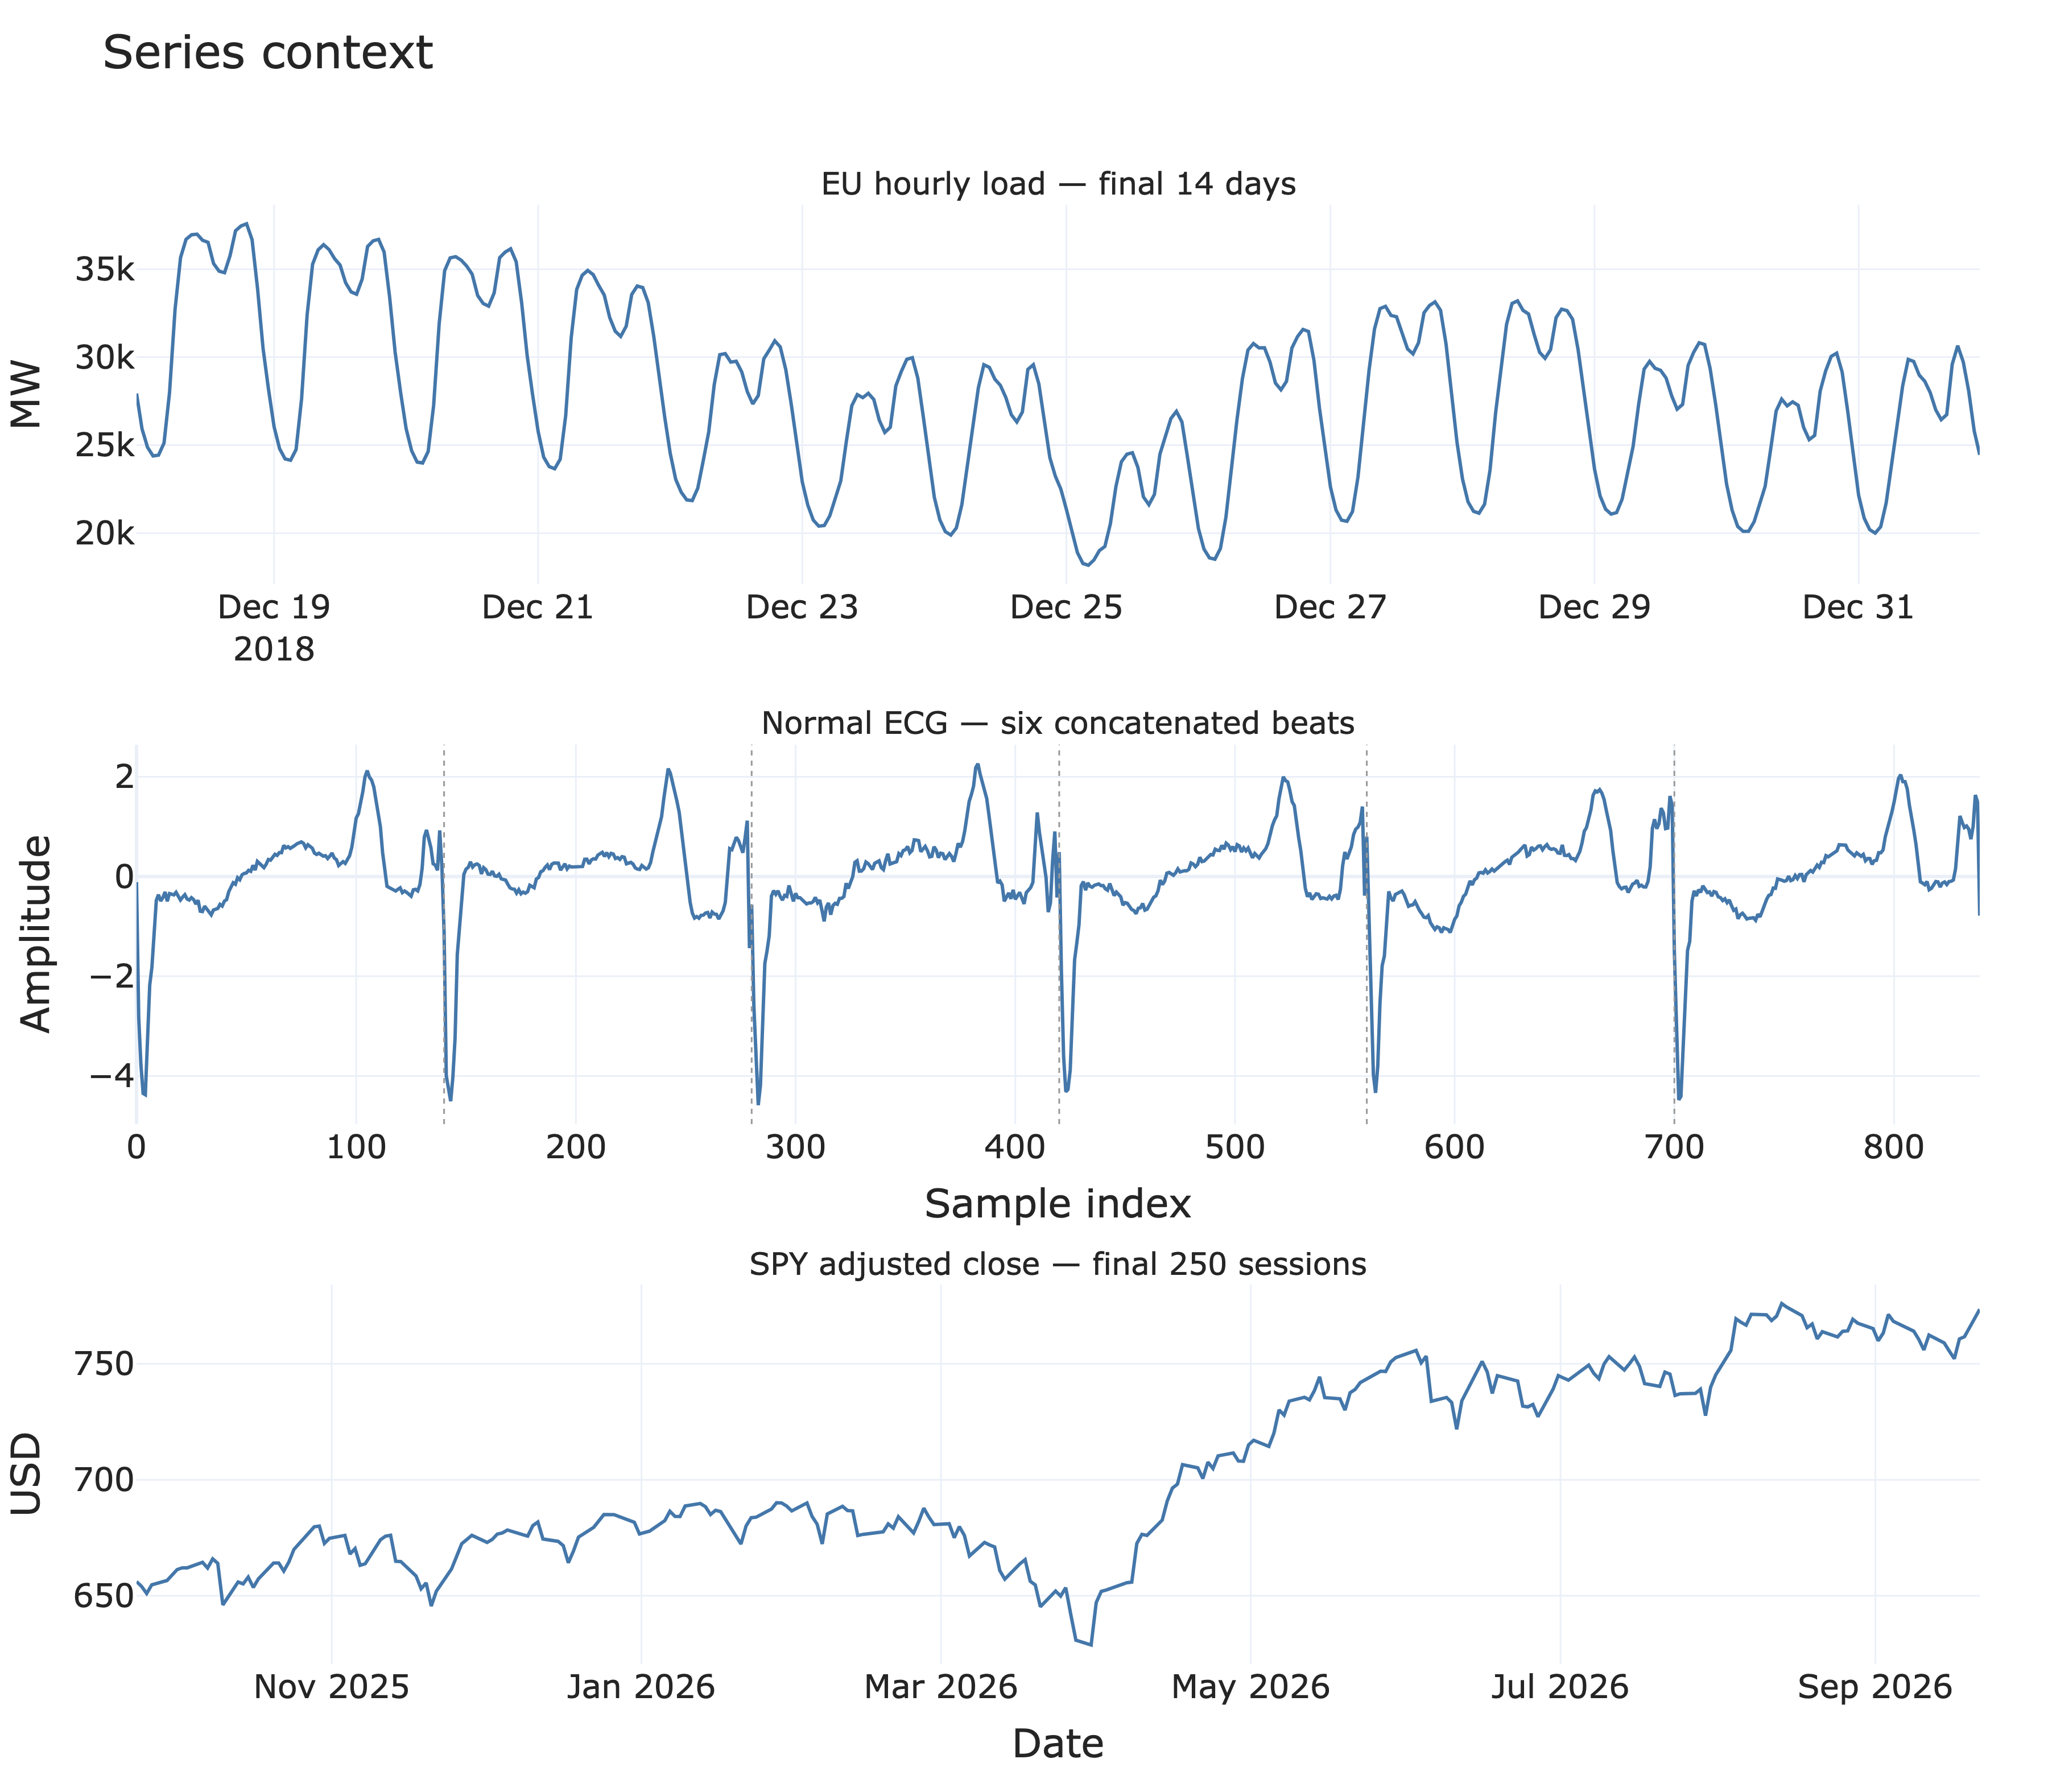

In [4]:
fig = make_subplots(
    rows=3,
    cols=1,
    vertical_spacing=0.11,
    subplot_titles=(
        "EU hourly load — final 14 days",
        "Normal ECG — six concatenated beats",
        "SPY adjusted close — final 250 sessions",
    ),
)

load = series["EU_Hourly_Load"]
fig.add_trace(
    go.Scatter(
        x=load.index[-24 * 14:],
        y=load.values[-24 * 14:],
        mode="lines",
        name="Observed load",
        showlegend=False,
        line=dict(color="#4477AA", width=2),
    ),
    row=1,
    col=1,
)

ecg = series["ECG_TF_Normal"]
fig.add_trace(
    go.Scatter(
        x=ecg.index,
        y=ecg.values,
        mode="lines",
        name="ECG amplitude",
        showlegend=False,
        line=dict(color="#4477AA", width=2),
    ),
    row=2,
    col=1,
)
for boundary in range(140, len(ecg.values), 140):
    fig.add_vline(x=boundary, line_width=1, line_dash="dot", line_color="#999999", row=2, col=1)

spy = series["SPY_AdjClose"]
fig.add_trace(
    go.Scatter(
        x=spy.index[-250:],
        y=spy.values[-250:],
        mode="lines",
        name="SPY adjusted close",
        showlegend=False,
        line=dict(color="#4477AA", width=2),
    ),
    row=3,
    col=1,
)

fig.update_yaxes(title_text="MW", row=1, col=1)
fig.update_yaxes(title_text="Amplitude", row=2, col=1)
fig.update_yaxes(title_text="USD", row=3, col=1)
fig.update_xaxes(title_text="Sample index", row=2, col=1)
fig.update_xaxes(title_text="Date", row=3, col=1)
fig.update_layout(
    title="Series context",
    hovermode="x unified",
)
show_and_save(
    fig, "series_overview",
    "Hourly load, normal ECG, and SPY adjusted-close overview",
    height=1050, bottom_margin=75,
)


Data sources: Darts/ENTSO-E energy data, TensorFlow ECG anomaly data, and Yahoo Finance SPY adjusted close.

The load panel contains repeated daily shapes with changing amplitude, which is a natural setting for both local and analogue methods. The ECG morphology repeats even more sharply, although the dotted beat boundaries mark the artificial concatenation. SPY has no comparable fixed cycle: its continuity is mainly persistence in the price level. These distinctions matter because the three algorithms define “similar structure” in different ways.

For every horizon $h\in\{1,7,14\}$, the final $10h$ observations are divided into ten adjacent test blocks. At each origin, the model sees only the prefix before that block. The methods are therefore compared on paired forecasts, and no test observation is reused within a horizon.

Three metrics are reported:

- **MAE** retains the physical unit of each series.
- **sMAPE** is symmetric and avoids division by the observed value alone, which is important for the zero-crossing ECG.
- **MASE** divides MAE by an in-sample naive difference: lag 24 for load, lag 140 for ECG, and lag 1 for SPY. A value below 1 means that the method improves on that series-specific naive scale.


In [5]:
def test_origins(n: int, horizon: int, n_splits: int = N_SPLITS) -> list[int]:
    first = n - n_splits * horizon
    return [first + split * horizon for split in range(n_splits)]


The series lengths give the following fixed test blocks:

| Series | Horizon | First test block | Last test block | Blocks |
|:--|--:|:--:|:--:|--:|
| EU hourly load | 1 | $[710,711)$ | $[719,720)$ | 10 |
| EU hourly load | 7 | $[650,657)$ | $[713,720)$ | 10 |
| EU hourly load | 14 | $[580,594)$ | $[706,720)$ | 10 |
| Normal ECG | 1 | $[830,831)$ | $[839,840)$ | 10 |
| Normal ECG | 7 | $[770,777)$ | $[833,840)$ | 10 |
| Normal ECG | 14 | $[700,714)$ | $[826,840)$ | 10 |
| SPY adjusted close | 1 | $[740,741)$ | $[749,750)$ | 10 |
| SPY adjusted close | 7 | $[680,687)$ | $[743,750)$ | 10 |
| SPY adjusted close | 14 | $[610,624)$ | $[736,750)$ | 10 |

The test origins move forward exactly one forecast block at a time. This makes the ten errors at a given series and horizon independent of overlap in their target intervals. Horizons should still be read separately: the 14-step task starts earlier and is intrinsically harder than the one-step task.

## 2. Methods

### 2.1 Local approximation

A state is represented by its latest $m$ samples. Historical states closest to the current state in Euclidean distance form a local neighborhood. Within that neighborhood, an affine map from state displacement to the next value is estimated by distance-weighted ridge regression. The intercept is the forecast at the current state; multi-step forecasts are produced recursively.

The implementation excludes states within one embedding window of the query time. Without this temporal exclusion, overlapping lag vectors would become nearly identical neighbours and create an unrealistically optimistic “forecast” from adjacent samples. The small ridge penalty only stabilizes the local linear solve; it does not turn the method into a global autoregression.

### 2.2 Maximum similarity

Chuchueva’s model compares the latest history of length $M$ with every earlier history that has an observed continuation of the requested length. For each candidate $z$, least squares fits

$$x \approx \alpha z + \beta,$$

and the candidate with the largest absolute linear correlation is selected. The same $\alpha$ and $\beta$ transform the candidate’s known continuation into the forecast. Unlike nearest-neighbour averaging, this method transfers one complete analogue and permits a level and scale adjustment.

### 2.3 Singular spectrum analysis

SSA arranges the training series into an $L\times K$ Hankel trajectory matrix, decomposes it with SVD, reconstructs the matrix from the leading eigentriples, and averages the anti-diagonals back to a one-dimensional signal. A recurrent SSA formula derived from the selected left singular vectors then extends the reconstructed signal.

The rank is chosen from 1–20 on the suffix of the **training prefix**: seven validation samples for horizons 1 and 7, and fourteen for horizon 14. The final SSA model is then refitted to the complete prefix at that rank. Using raw explained energy alone would often select rank 1 for a high-level series because the mean dominates the trajectory matrix; chronological validation asks the more relevant question of how much of the remaining structure is useful for forecasting.

SSA is global: every retained component contributes to every forecast. Local approximation and maximum similarity are local/analogue methods: they use only a neighbourhood or one historical episode. This difference is central to the later comparison.


The forecasting parameters were fixed from those time scales before evaluating the test blocks:

| Series | Local state $m$ | Neighbours $k$ | Similarity window $M$ | SSA window $L$ | Scale represented |
|:--|--:|--:|--:|--:|:--|
| EU hourly load | 24 | 80 | 168 | 168 | One day locally; one week for analogues and SSA |
| Normal ECG | 32 | 80 | 140 | 140 | Partial beat locally; one full beat for pattern transfer and SSA |
| SPY adjusted close | 10 | 40 | 60 | 60 | About two trading weeks locally; one quarter globally |

The windows encode process scale rather than being optimized on the held-out blocks. Load uses a day as a local state and a week as the longer analogue/SSA context. ECG uses a short morphological state but one full beat for pattern transfer and SSA. SPY uses short recent context for local dynamics and roughly one trading quarter for the global methods. This keeps the comparison interpretable and avoids selecting a different parameter after seeing every test result.


In [6]:
def local_library(train: np.ndarray, dimension: int, theiler: int) -> tuple[np.ndarray, np.ndarray]:
    train = np.asarray(train, dtype=float)
    states = sliding_window_view(train, dimension)[:-1]
    targets = train[dimension:]
    target_times = np.arange(dimension, len(train))
    keep = target_times <= len(train) - theiler - 1
    return states[keep], targets[keep]


def local_approximation_forecast(train: np.ndarray, horizon: int, dimension: int,
                                 neighbors: int) -> tuple[np.ndarray, dict]:
    train = np.asarray(train, dtype=float)
    center = float(np.mean(train))
    scale = float(np.std(train)) or 1.0
    normalized = (train - center) / scale
    states, targets = local_library(normalized, dimension, theiler=dimension)
    k = min(neighbors, len(states))
    history = normalized.tolist()
    predictions = []
    first_distances = None
    first_indices = None

    for step in range(horizon):
        query = np.asarray(history[-dimension:])
        distances = np.sqrt(np.mean((states - query) ** 2, axis=1))
        indices = np.argpartition(distances, k - 1)[:k]
        indices = indices[np.argsort(distances[indices])]
        local_distances = distances[indices]
        bandwidth = max(float(local_distances[-1]), 1e-8)
        weights = np.exp(-0.5 * (local_distances / bandwidth) ** 2)

        offsets = states[indices] - query
        design = np.column_stack([np.ones(k), offsets])
        weighted_design = design * np.sqrt(weights[:, None])
        weighted_target = targets[indices] * np.sqrt(weights)
        penalty = np.diag([0.0] + [1e-3] * dimension)
        coefficients = np.linalg.solve(weighted_design.T @ weighted_design + penalty,
                                       weighted_design.T @ weighted_target)
        prediction = float(coefficients[0])
        history.append(prediction)
        predictions.append(center + scale * prediction)

        if step == 0:
            first_distances = local_distances.copy()
            first_indices = indices.copy()

    diagnostics = {
        "nearest_distance": float(first_distances[0]),
        "neighbour_radius": float(first_distances[-1]),
        "neighbour_indices": first_indices,
        "library_states": states,
        "query": normalized[-dimension:],
        "center": center,
        "scale": scale,
    }
    return np.asarray(predictions), diagnostics


def maximum_similarity_forecast(train: np.ndarray, horizon: int, window: int) -> tuple[np.ndarray, dict]:
    train = np.asarray(train, dtype=float)
    if len(train) < window + horizon + 2:
        raise ValueError("The training prefix is too short for maximum-similarity forecasting")

    blocks = sliding_window_view(train, window + horizon)
    candidates = blocks[:, :window]
    continuations = blocks[:, window:]
    current = train[-window:]

    candidate_mean = candidates.mean(axis=1)
    current_mean = float(current.mean())
    candidate_centered = candidates - candidate_mean[:, None]
    current_centered = current - current_mean
    covariance = candidate_centered @ current_centered
    candidate_ss = np.sum(candidate_centered ** 2, axis=1)
    current_ss = float(np.sum(current_centered ** 2))
    denominator = np.sqrt(candidate_ss * current_ss)
    correlations = np.divide(covariance, denominator, out=np.zeros_like(covariance), where=denominator > 1e-12)

    best = int(np.argmax(np.abs(correlations)))
    alpha = float(covariance[best] / candidate_ss[best]) if candidate_ss[best] > 1e-12 else 0.0
    beta = current_mean - alpha * float(candidate_mean[best])
    prediction = alpha * continuations[best] + beta
    transformed_history = alpha * candidates[best] + beta

    diagnostics = {
        "candidate_start": best,
        "lag": len(train) - window - best,
        "correlation": float(correlations[best]),
        "alpha": alpha,
        "beta": beta,
        "current": current,
        "transformed_history": transformed_history,
        "base_continuation": continuations[best],
    }
    return np.asarray(prediction), diagnostics


def diagonal_averaging(matrix: np.ndarray) -> np.ndarray:
    rows, columns = matrix.shape
    values = np.zeros(rows + columns - 1)
    counts = np.zeros(rows + columns - 1)
    for row in range(rows):
        values[row:row + columns] += matrix[row]
        counts[row:row + columns] += 1
    return values / counts


def ssa_decomposition(train: np.ndarray, window: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    trajectory = sliding_window_view(train, window).T
    return np.linalg.svd(trajectory, full_matrices=False)


def ssa_recurrent_prediction(u: np.ndarray, singular_values: np.ndarray, vt: np.ndarray,
                             horizon: int, rank: int) -> tuple[np.ndarray, np.ndarray]:
    window = u.shape[0]
    reconstructed_matrix = (u[:, :rank] * singular_values[:rank]) @ vt[:rank]
    reconstructed = diagonal_averaging(reconstructed_matrix)

    final_coordinates = u[-1, :rank]
    denominator = 1.0 - float(np.sum(final_coordinates ** 2))
    if denominator < 1e-6:
        raise ValueError("Unstable SSA recurrence for this rank")
    recurrence = (u[:-1, :rank] @ final_coordinates) / denominator

    history = reconstructed.tolist()
    prediction = []
    for _ in range(horizon):
        next_value = float(np.dot(recurrence, history[-(window - 1):]))
        history.append(next_value)
        prediction.append(next_value)

    return np.asarray(prediction), reconstructed


def ssa_forecast(train: np.ndarray, horizon: int, window: int,
                 rank_cap: int = 20) -> tuple[np.ndarray, dict]:
    train = np.asarray(train, dtype=float)
    validation_horizon = 14 if horizon == 14 else 7
    tuning_train = train[:-validation_horizon]
    validation = train[-validation_horizon:]
    tuning_u, tuning_s, tuning_vt = ssa_decomposition(tuning_train, window)

    rank_scores = []
    maximum_rank = min(rank_cap, window - 2, len(tuning_s))
    for rank in range(1, maximum_rank + 1):
        try:
            validation_prediction, _ = ssa_recurrent_prediction(
                tuning_u, tuning_s, tuning_vt, validation_horizon, rank
            )
        except ValueError:
            continue
        denominator = np.abs(validation) + np.abs(validation_prediction)
        terms = np.divide(
            2 * np.abs(validation - validation_prediction), denominator,
            out=np.zeros_like(denominator), where=denominator > 1e-12,
        )
        rank_scores.append((float(100 * np.mean(terms)), rank))

    validation_score, rank = min(rank_scores)
    u, singular_values, vt = ssa_decomposition(train, window)
    prediction, reconstructed = ssa_recurrent_prediction(u, singular_values, vt, horizon, rank)
    energy = singular_values ** 2
    cumulative_energy = np.cumsum(energy) / energy.sum()

    diagnostics = {
        "rank": rank,
        "retained_energy": float(cumulative_energy[rank - 1]),
        "validation_smape": validation_score,
        "singular_values": singular_values,
        "cumulative_energy": cumulative_energy,
        "reconstructed": reconstructed,
    }
    return prediction, diagnostics


def naive_forecast(train: np.ndarray, horizon: int, season: int) -> np.ndarray:
    history = list(np.asarray(train, dtype=float))
    prediction = []
    for _ in range(horizon):
        next_value = history[-season]
        history.append(next_value)
        prediction.append(next_value)
    return np.asarray(prediction)


def mae(actual: np.ndarray, predicted: np.ndarray) -> float:
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))


def smape(actual: np.ndarray, predicted: np.ndarray) -> float:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual) + np.abs(predicted)
    terms = np.divide(2 * np.abs(actual - predicted), denominator,
                      out=np.zeros_like(denominator), where=denominator > 1e-12)
    return float(100 * np.mean(terms))


def mase(actual: np.ndarray, predicted: np.ndarray, train: np.ndarray, season: int) -> float:
    scale = float(np.mean(np.abs(train[season:] - train[:-season])))
    return mae(actual, predicted) / scale if scale > 1e-12 else np.nan


The implementation keeps the three mechanisms separate. The local model predicts from a weighted neighbourhood but never changes its historical library during recursive forecasting. Maximum similarity searches directly for a single affine-matched episode with a fully observed continuation. SSA reconstructs the whole prefix before applying its recurrent relation. These choices make the comparison traceable: when a method fails, its source of information is still visible.

## 3. Walk-forward forecasts


In [7]:
rows = []
forecast_rows = []
diagnostic_rows = []
last_diagnostics = {}

for item in series.values():
    for horizon in HORIZONS:
        origins = test_origins(len(item.values), horizon)
        for split, origin in enumerate(origins, start=1):
            train = item.values[:origin]
            actual = item.values[origin:origin + horizon]

            local_prediction, local_diag = local_approximation_forecast(
                train, horizon, item.local_dimension, item.local_neighbors
            )
            similarity_prediction, similarity_diag = maximum_similarity_forecast(
                train, horizon, item.similarity_window
            )
            ssa_prediction, ssa_diag = ssa_forecast(train, horizon, item.ssa_window)
            baseline_prediction = naive_forecast(train, horizon, item.season)

            predictions = {
                "Local approximation": local_prediction,
                "Maximum similarity": similarity_prediction,
                "SSA": ssa_prediction,
                "Naive baseline": baseline_prediction,
            }

            for method, predicted in predictions.items():
                rows.append({
                    "series": item.key,
                    "series_label": item.label,
                    "horizon": horizon,
                    "split": split,
                    "origin": origin,
                    "method": method,
                    "mae": mae(actual, predicted),
                    "smape": smape(actual, predicted),
                    "mase": mase(actual, predicted, train, item.season),
                })
                for step, (observed, estimate) in enumerate(zip(actual, predicted), start=1):
                    forecast_rows.append({
                        "series": item.key,
                        "series_label": item.label,
                        "horizon": horizon,
                        "split": split,
                        "origin": origin,
                        "method": method,
                        "step": step,
                        "actual": observed,
                        "predicted": estimate,
                    })

            diagnostic_rows.append({
                "series": item.key,
                "horizon": horizon,
                "split": split,
                "origin": origin,
                "local_nearest_distance": local_diag["nearest_distance"],
                "local_neighbour_radius": local_diag["neighbour_radius"],
                "similarity_lag": similarity_diag["lag"],
                "similarity_correlation": similarity_diag["correlation"],
                "similarity_alpha": similarity_diag["alpha"],
                "similarity_beta": similarity_diag["beta"],
                "ssa_rank": ssa_diag["rank"],
                "ssa_retained_energy": ssa_diag["retained_energy"],
                "ssa_validation_smape": ssa_diag["validation_smape"],
            })

            if horizon == 14 and split == N_SPLITS:
                last_diagnostics[item.key] = {
                    "origin": origin,
                    "actual": actual,
                    "local": local_diag,
                    "similarity": similarity_diag,
                    "ssa": ssa_diag,
                    "predictions": predictions,
                }

results = pd.DataFrame(rows)
forecasts = pd.DataFrame(forecast_rows)
diagnostics = pd.DataFrame(diagnostic_rows)

summary = (
    results.groupby(["series", "series_label", "horizon", "method"], as_index=False)
    .agg(
        mean_smape=("smape", "mean"),
        median_smape=("smape", "median"),
        mean_mase=("mase", "mean"),
        median_mase=("mase", "median"),
        mean_mae=("mae", "mean"),
        median_mae=("mae", "median"),
    )
)

results.to_csv(LAB_DIR / "forecast_results_raw.csv", index=False)
forecasts.to_csv(LAB_DIR / "forecast_paths.csv", index=False)
diagnostics.to_csv(LAB_DIR / "method_diagnostics.csv", index=False)
summary.to_csv(LAB_DIR / "forecast_results_summary.csv", index=False)

for item in series.values():
    view = summary[summary["series"] == item.key].copy()
    view["Method"] = pd.Categorical(view["method"], METHODS, ordered=True)
    view = view.sort_values(["horizon", "Method"])
    view = view.rename(columns={
        "horizon": "h",
        "mean_smape": "mean sMAPE, %",
        "median_smape": "median sMAPE, %",
        "mean_mase": "mean MASE",
        "mean_mae": f"mean MAE, {item.unit}",
    })
    show_table(
        view[["h", "Method", "mean sMAPE, %", "median sMAPE, %", "mean MASE", f"mean MAE, {item.unit}"]],
        f"Forecast accuracy — {item.label}", precision=3, max_width=25,
    )


+---------------------------------------------------------------------------------------+
|                           Forecast accuracy — EU hourly load                          |
+----+---------------------+---------------+-----------------+-----------+--------------+
| h  | Method              | mean sMAPE, % | median sMAPE, % | mean MASE | mean MAE, MW |
+----+---------------------+---------------+-----------------+-----------+--------------+
| 1  | Local approximation | 1.996         | 2.126           | 0.214     | 556.476      |
| 1  | Maximum similarity  | 4.352         | 3.682           | 0.465     | 1207.255     |
| 1  | SSA                 | 5.221         | 4.641           | 0.560     | 1453.426     |
| 1  | Naive baseline      | 5.565         | 4.660           | 0.589     | 1529.300     |
| 7  | Local approximation | 3.559         | 2.792           | 0.345     | 914.470      |
| 7  | Maximum similarity  | 6.014         | 5.443           | 0.589     | 1555.522     |
| 7  | SSA

Electricity load gives the clearest result. Local approximation has the lowest mean sMAPE at every horizon: **2.00%**, **3.56%** and **4.97%** for 1, 7 and 14 hours. Its mean MASE rises from 0.21 to 0.47 but remains well below 1, so the improvement is not merely relative to the other two proposed methods; it is also substantial relative to the daily seasonal scale. SSA becomes the second-best method at horizons 7 and 14, with mean sMAPE of 5.60% and 6.48%. Maximum similarity is competitive at short horizons but reaches 12.09% at 14 hours because one analogue cannot reliably reproduce the next peak amplitude.

The ECG ranking depends on the error definition. Maximum similarity is clearly best one step ahead (18.02% mean sMAPE, 0.71 MASE). At seven steps, the seasonal naive forecast has the lowest sMAPE (43.67%), while local approximation has the lowest absolute error (MAE 0.191 and MASE 0.68). At fourteen steps, the same disagreement appears in reverse form: the naive forecast has the lowest sMAPE (51.66%), but maximum similarity has the lowest MAE (0.264) and MASE (0.91). Samples near zero or with an incorrect sign are heavily penalized by sMAPE, so both the percentage and absolute-error columns are needed for this centered waveform.

SPY does not show a robust gain over persistence. Maximum similarity improves the one-step mean sMAPE only slightly, from 0.661% for the random-walk baseline to 0.629%. At seven steps, SSA and the baseline are effectively tied in mean sMAPE (1.125% versus 1.133%), while the baseline has the better median (0.685% versus 1.087%). At fourteen steps the baseline is best at 1.795%, compared with 2.254% for SSA. Every SPY mean MASE exceeds 1.25, indicating that the final test regime is harder than the historical one-step scale and that low percentage errors in the price level should not be read as predictable returns.



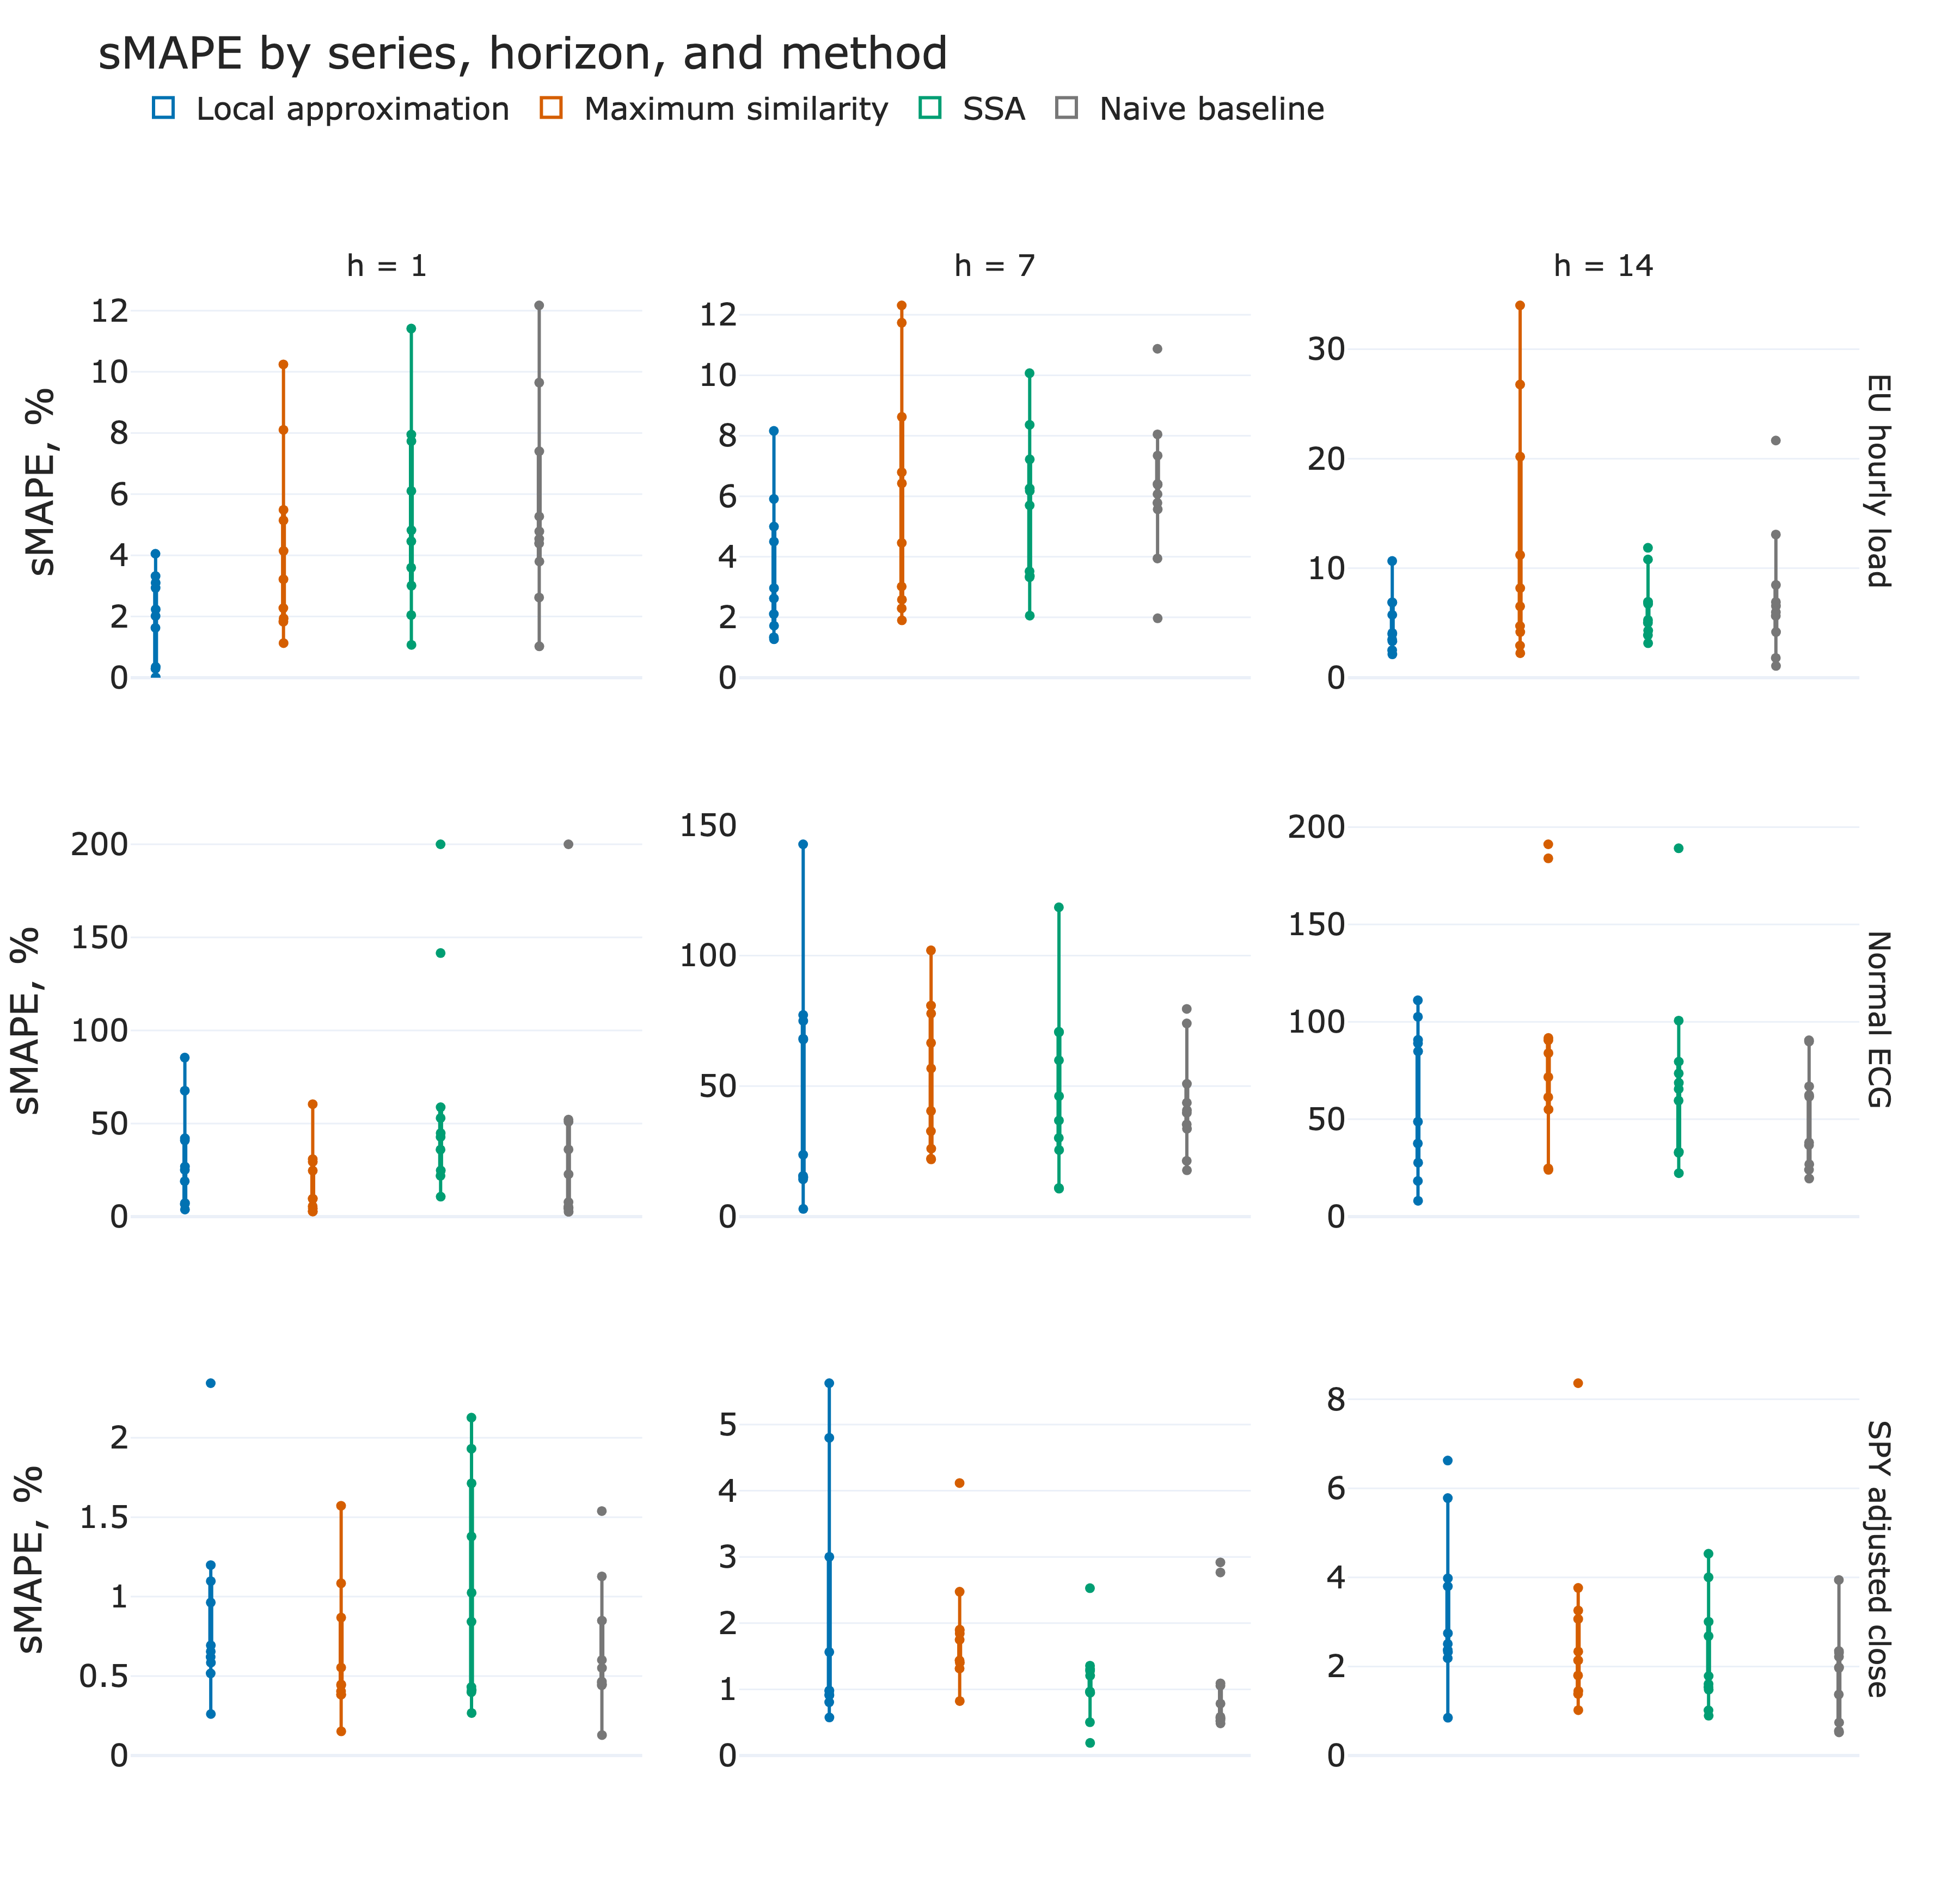

In [8]:
fig = make_subplots(
    rows=3, cols=3, shared_yaxes=False,
    horizontal_spacing=0.055, vertical_spacing=0.10,
    row_titles=[item.label for item in series.values()],
    column_titles=[f"h = {h}" for h in HORIZONS],
)

for row, item in enumerate(series.values(), start=1):
    for col, horizon in enumerate(HORIZONS, start=1):
        panel = results[(results["series"] == item.key) & (results["horizon"] == horizon)]
        for method in METHODS:
            values = panel.loc[panel["method"] == method, "smape"]
            fig.add_trace(go.Box(
                y=values,
                name=method,
                legendgroup=method,
                marker=dict(color=METHOD_COLORS[method], size=6),
                line=dict(color=METHOD_COLORS[method], width=2),
                fillcolor="rgba(255,255,255,0)",
                boxpoints="all",
                jitter=0.22,
                pointpos=0,
                showlegend=(row == 1 and col == 1),
                hovertemplate=f"{method}<br>sMAPE=%{{y:.2f}}%<extra></extra>",
            ), row=row, col=col)
        fig.update_xaxes(showticklabels=False, row=row, col=col)
        fig.update_yaxes(title_text="sMAPE, %" if col == 1 else None, rangemode="tozero", row=row, col=col)

fig.update_layout(
    title="sMAPE by series, horizon, and method",
    boxmode="group",
)
show_and_save(
    fig, "smape_boxplots",
    "sMAPE distributions by series, horizon, and method",
    height=1150, top_margin=175, bottom_margin=75, legend_y=1.10,
)


Each box contains ten non-overlapping chronological test blocks, and each point is one block error.

The distributions reinforce the table rather than merely repeating its means. For load, the local-approximation points stay below most alternatives in all three panels; maximum similarity develops a 34.0% error block at horizon 14, showing the risk of committing to one historical continuation. ECG is much less stable: several methods reach extreme percentage errors, including 200% when prediction and observation have opposing signs. With only ten blocks per task, those tails are part of the result and should not be hidden by reporting a single average.

The SPY boxes overlap strongly. SSA's narrow lead in the seven-step mean comes from a few accurate blocks, whereas the baseline has the lower median. This is not evidence of a repeatable superiority. The paired points instead support a conservative conclusion: on this price-level segment, none of the three methods consistently improves on carrying the latest price forward.


## 4. What each method actually used

Aggregate errors alone do not show whether an analogue was genuinely similar or whether an SSA forecast relied on a compact signal subspace. The next diagnostics use the final 14-step forecast origin for each series. They are examples rather than additional test cases; the accuracy summaries above still use all ten blocks.



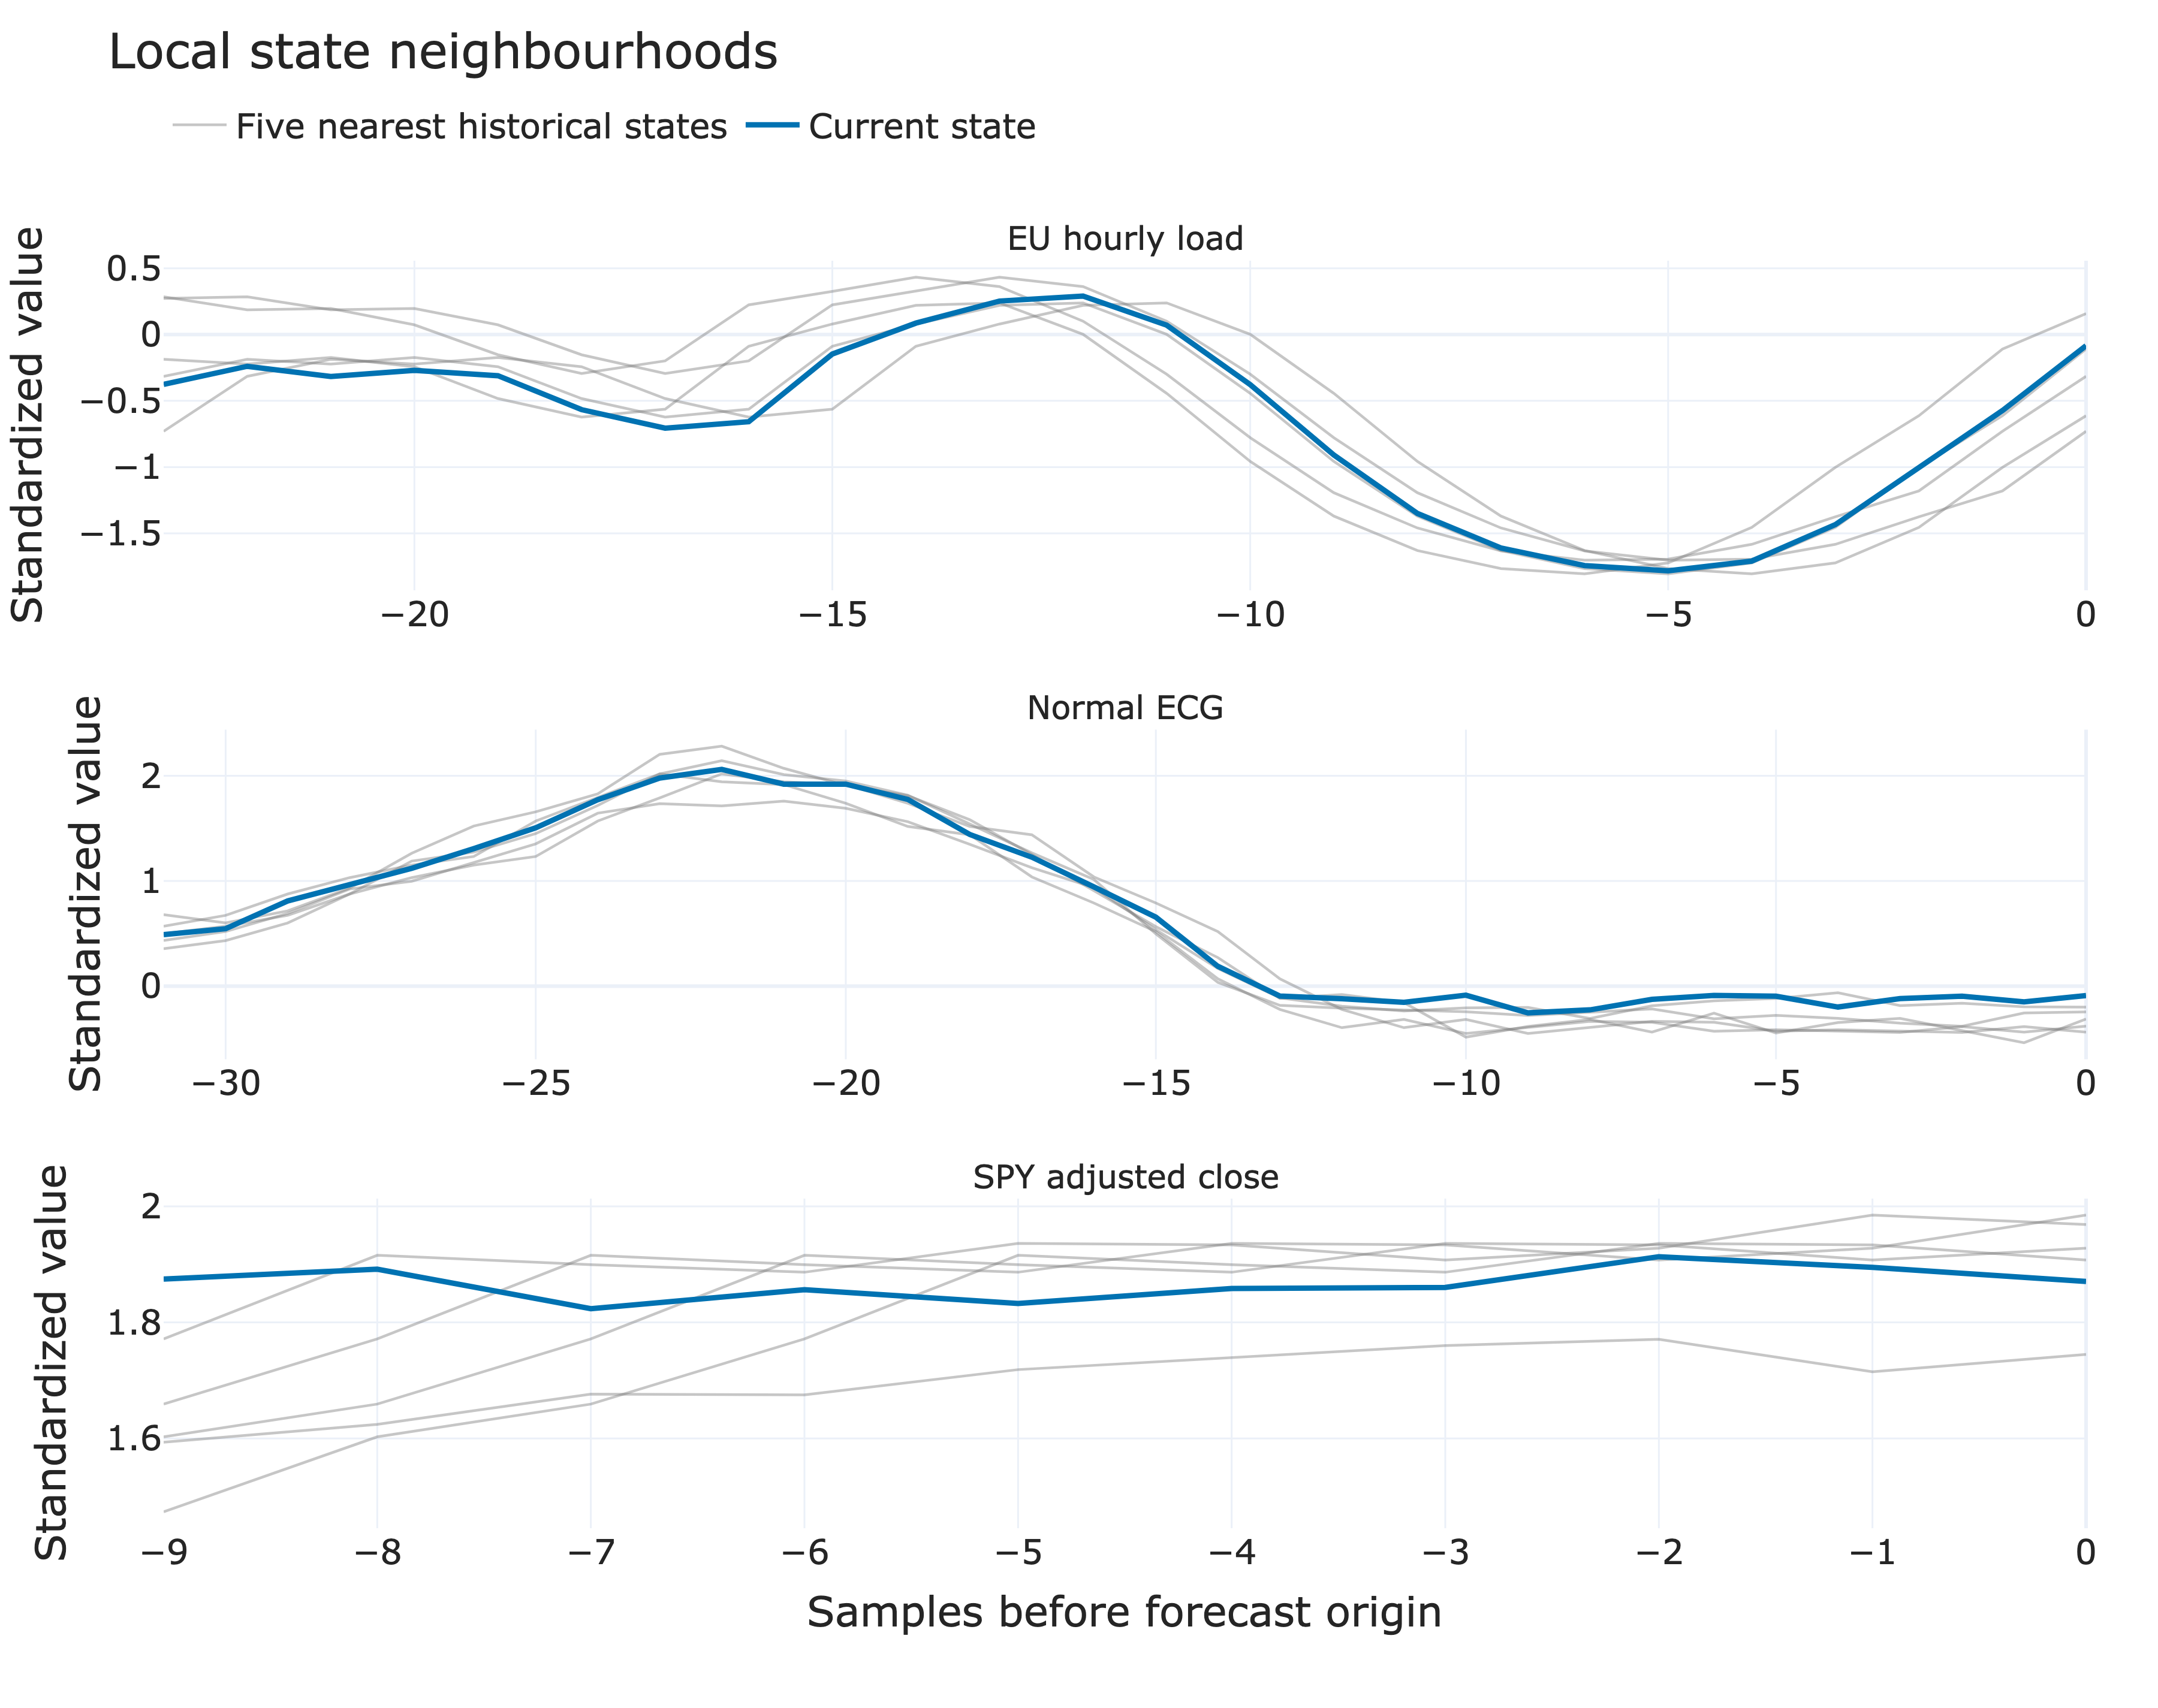

In [9]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.11,
    subplot_titles=[item.label for item in series.values()],
)

for row, item in enumerate(series.values(), start=1):
    diagnostic = last_diagnostics[item.key]["local"]
    query = diagnostic["query"]
    library = diagnostic["library_states"]
    nearest = diagnostic["neighbour_indices"][:5]
    x = np.arange(-len(query) + 1, 1)

    for position, index in enumerate(nearest):
        fig.add_trace(
            go.Scatter(
                x=x,
                y=library[index],
                mode="lines",
                name="Five nearest historical states",
                legendgroup="neighbours",
                showlegend=row == 1 and position == 0,
                line=dict(color="rgba(120,120,120,0.42)", width=1.5),
                hovertemplate="Relative step=%{x}<br>standardized value=%{y:.2f}<extra>Historical neighbour</extra>",
            ),
            row=row,
            col=1,
        )

    fig.add_trace(
        go.Scatter(
            x=x,
            y=query,
            mode="lines",
            name="Current state",
            legendgroup="query",
            showlegend=row == 1,
            line=dict(color=METHOD_COLORS["Local approximation"], width=3),
            hovertemplate="Relative step=%{x}<br>standardized value=%{y:.2f}<extra>Current state</extra>",
        ),
        row=row,
        col=1,
    )
    fig.update_yaxes(title_text="Standardized value", row=row, col=1)

fig.update_xaxes(title_text="Samples before forecast origin", row=3, col=1)
fig.update_layout(title="Local state neighbourhoods")
show_and_save(
    fig, "local_neighbourhoods",
    "Current states and nearest historical neighbours",
    height=950, top_margin=145, bottom_margin=100, legend_y=1.08,
)


The five nearest states are shown for readability, while each local regression uses the full neighbour set.

The load query follows a daily fall-and-rise pattern that is also present in several historical states. At the final origin its nearest standardized distance is 0.056; the full 80-neighbour radius is 0.819, so the distance weights are important because not every retained neighbour is equally close. ECG has a similarly recognizable local morphology (nearest distance 0.125), but the later recursive steps can cross into a different part of the beat and accumulate error.

SPY's neighbours are close mainly because short price paths are smooth and occupy a similar level. Their slopes already disagree within the ten-sample state. The nearest distance of 0.074 therefore measures local geometric proximity, not a recurring market regime. This explains why the method can look plausible for one step yet drift badly over the final 14-step path.



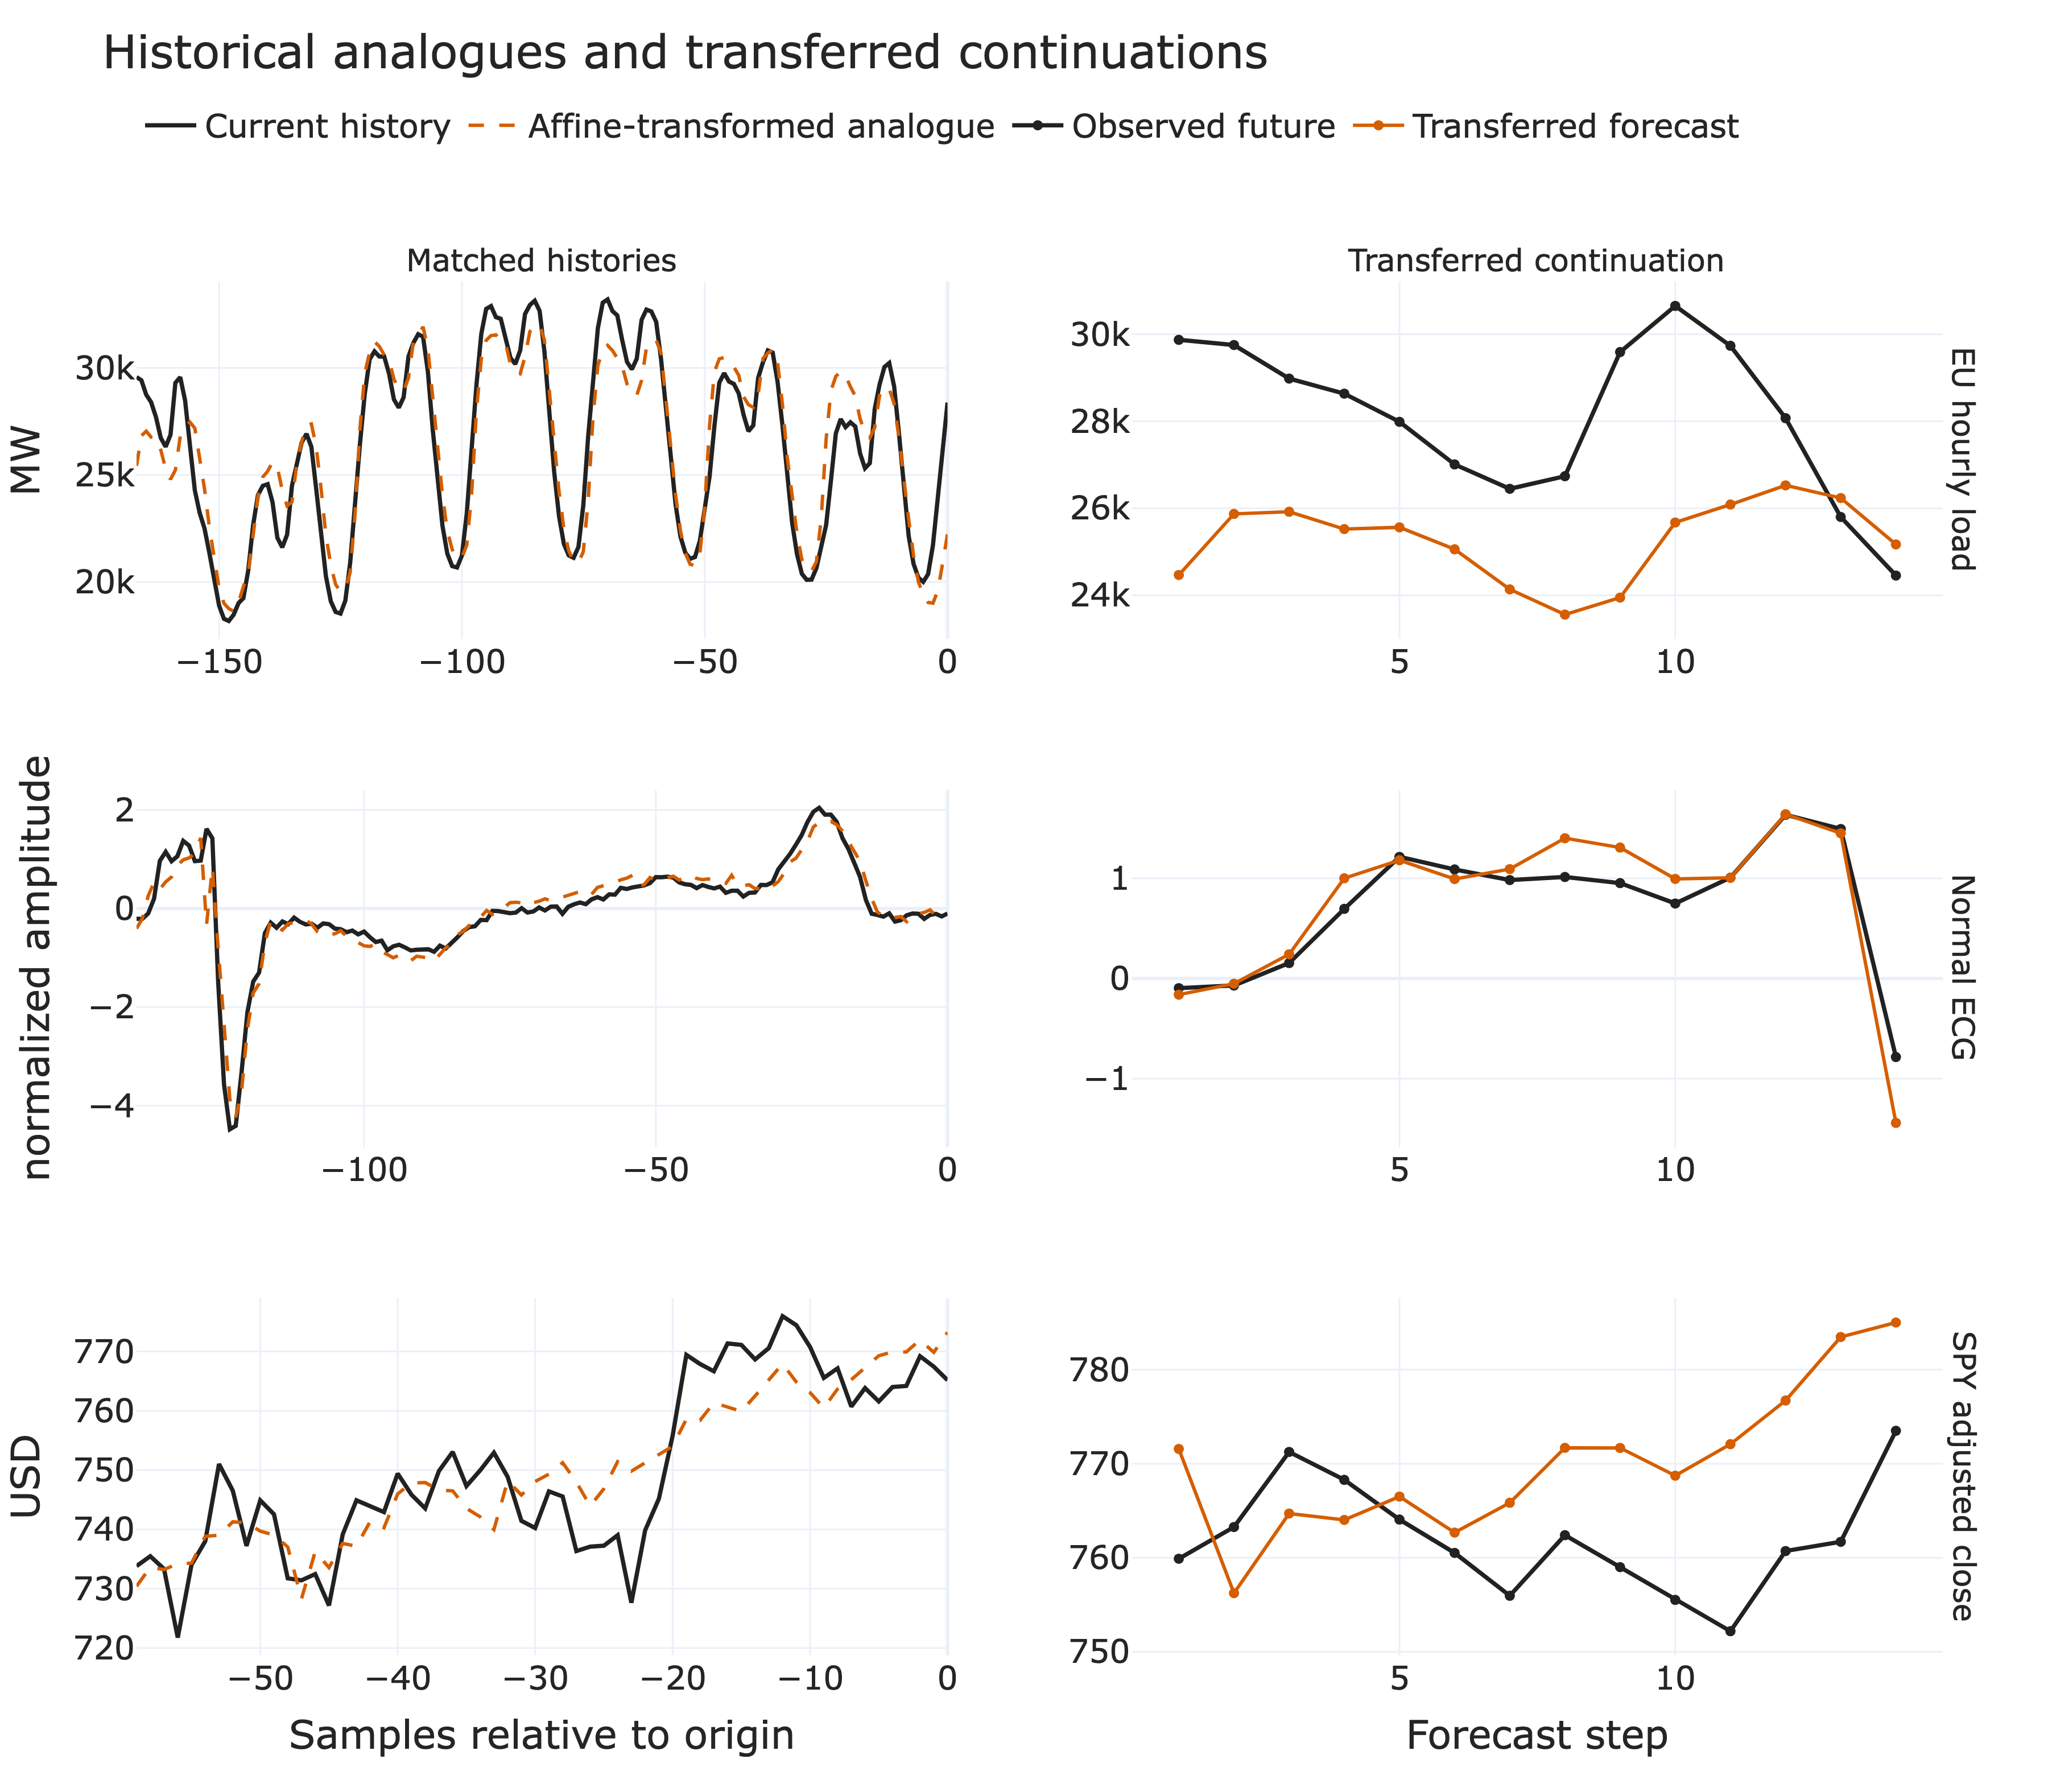

+------------------------------------------------------------------------------------------+
|                Maximum-similarity diagnostics for the final 14-step block                |
+--------------------+----------------+-------------+---------+---------+------------------+
| Series             | Historical lag | Correlation | Scale α | Shift β | 14-step sMAPE, % |
+--------------------+----------------+-------------+---------+---------+------------------+
| EU hourly load     | 217            | 0.929       | 0.828   | 920.424 | 11.204           |
| Normal ECG         | 139            | 0.956       | 0.987   | 0.047   | 24.032           |
| SPY adjusted close | 224            | 0.860       | 0.855   | 204.019 | 1.383            |
+--------------------+----------------+-------------+---------+---------+------------------+


In [10]:
fig = make_subplots(
    rows=3, cols=2, horizontal_spacing=0.10, vertical_spacing=0.11,
    column_titles=("Matched histories", "Transferred continuation"),
    row_titles=[item.label for item in series.values()],
)
similarity_rows = []

for row, item in enumerate(series.values(), start=1):
    record = last_diagnostics[item.key]
    diagnostic = record["similarity"]
    current = diagnostic["current"]
    match = diagnostic["transformed_history"]
    context_x = np.arange(-len(current) + 1, 1)
    future_x = np.arange(1, 15)

    fig.add_trace(
        go.Scatter(
            x=context_x,
            y=current,
            mode="lines",
            name="Current history",
            legendgroup="current",
            showlegend=row == 1,
            line=dict(color="#222222", width=2.5),
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=context_x,
            y=match,
            mode="lines",
            name="Affine-transformed analogue",
            legendgroup="analogue",
            showlegend=row == 1,
            line=dict(color=METHOD_COLORS["Maximum similarity"], width=2, dash="dash"),
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=future_x,
            y=record["actual"],
            mode="lines+markers",
            name="Observed future",
            legendgroup="observed",
            showlegend=row == 1,
            line=dict(color="#222222", width=2.5),
            marker=dict(size=6),
        ),
        row=row,
        col=2,
    )
    fig.add_trace(
        go.Scatter(
            x=future_x,
            y=record["predictions"]["Maximum similarity"],
            mode="lines+markers",
            name="Transferred forecast",
            legendgroup="transferred",
            showlegend=row == 1,
            line=dict(color=METHOD_COLORS["Maximum similarity"], width=2),
            marker=dict(size=6),
        ),
        row=row,
        col=2,
    )

    fig.update_yaxes(title_text=item.unit, row=row, col=1)
    similarity_rows.append({
        "Series": item.label,
        "Historical lag": diagnostic["lag"],
        "Correlation": diagnostic["correlation"],
        "Scale α": diagnostic["alpha"],
        "Shift β": diagnostic["beta"],
        "14-step sMAPE, %": smape(record["actual"], record["predictions"]["Maximum similarity"]),
    })

fig.update_xaxes(title_text="Samples relative to origin", row=3, col=1)
fig.update_xaxes(title_text="Forecast step", row=3, col=2)
fig.update_layout(title="Historical analogues and transferred continuations")
show_and_save(
    fig, "maximum_similarity_examples",
    "Matched histories and transferred 14-step continuations",
    height=1050, top_margin=165, bottom_margin=80, legend_y=1.09,
)

show_table(pd.DataFrame(similarity_rows), "Maximum-similarity diagnostics for the final 14-step block",
           precision=3, max_width=26)


The final 14-step test block is shown. The forecast in the right column uses the same affine map fitted to the histories in the left column.

For the final load forecast, the selected history is 217 hours old and has correlation 0.929 after an affine rescaling. The left panel confirms a good in-sample shape match, but the transferred continuation stays too low during the next peak and produces 11.20% sMAPE. This is the central limitation of the method: similarity of histories is only useful when it also implies similarity of their futures.

ECG provides the strongest analogue. A lag of 139 samples nearly aligns the preceding beat with the current one ($r=0.956$, $\alpha=0.987$), and the transferred continuation follows most of the final path, with 24.03% sMAPE. SPY also has a visually respectable matched history ($r=0.860$), yet its analogue rises while the observed price initially falls; its final-block error is 1.38%.

The one-step results require an additional qualification. For every one-step load and SPY origin, the maximum-correlation history is at lag 1. Those windows overlap almost completely, so the small one-step error is primarily a persistence effect permitted by the original search rule, not evidence that a distant analogue was discovered.



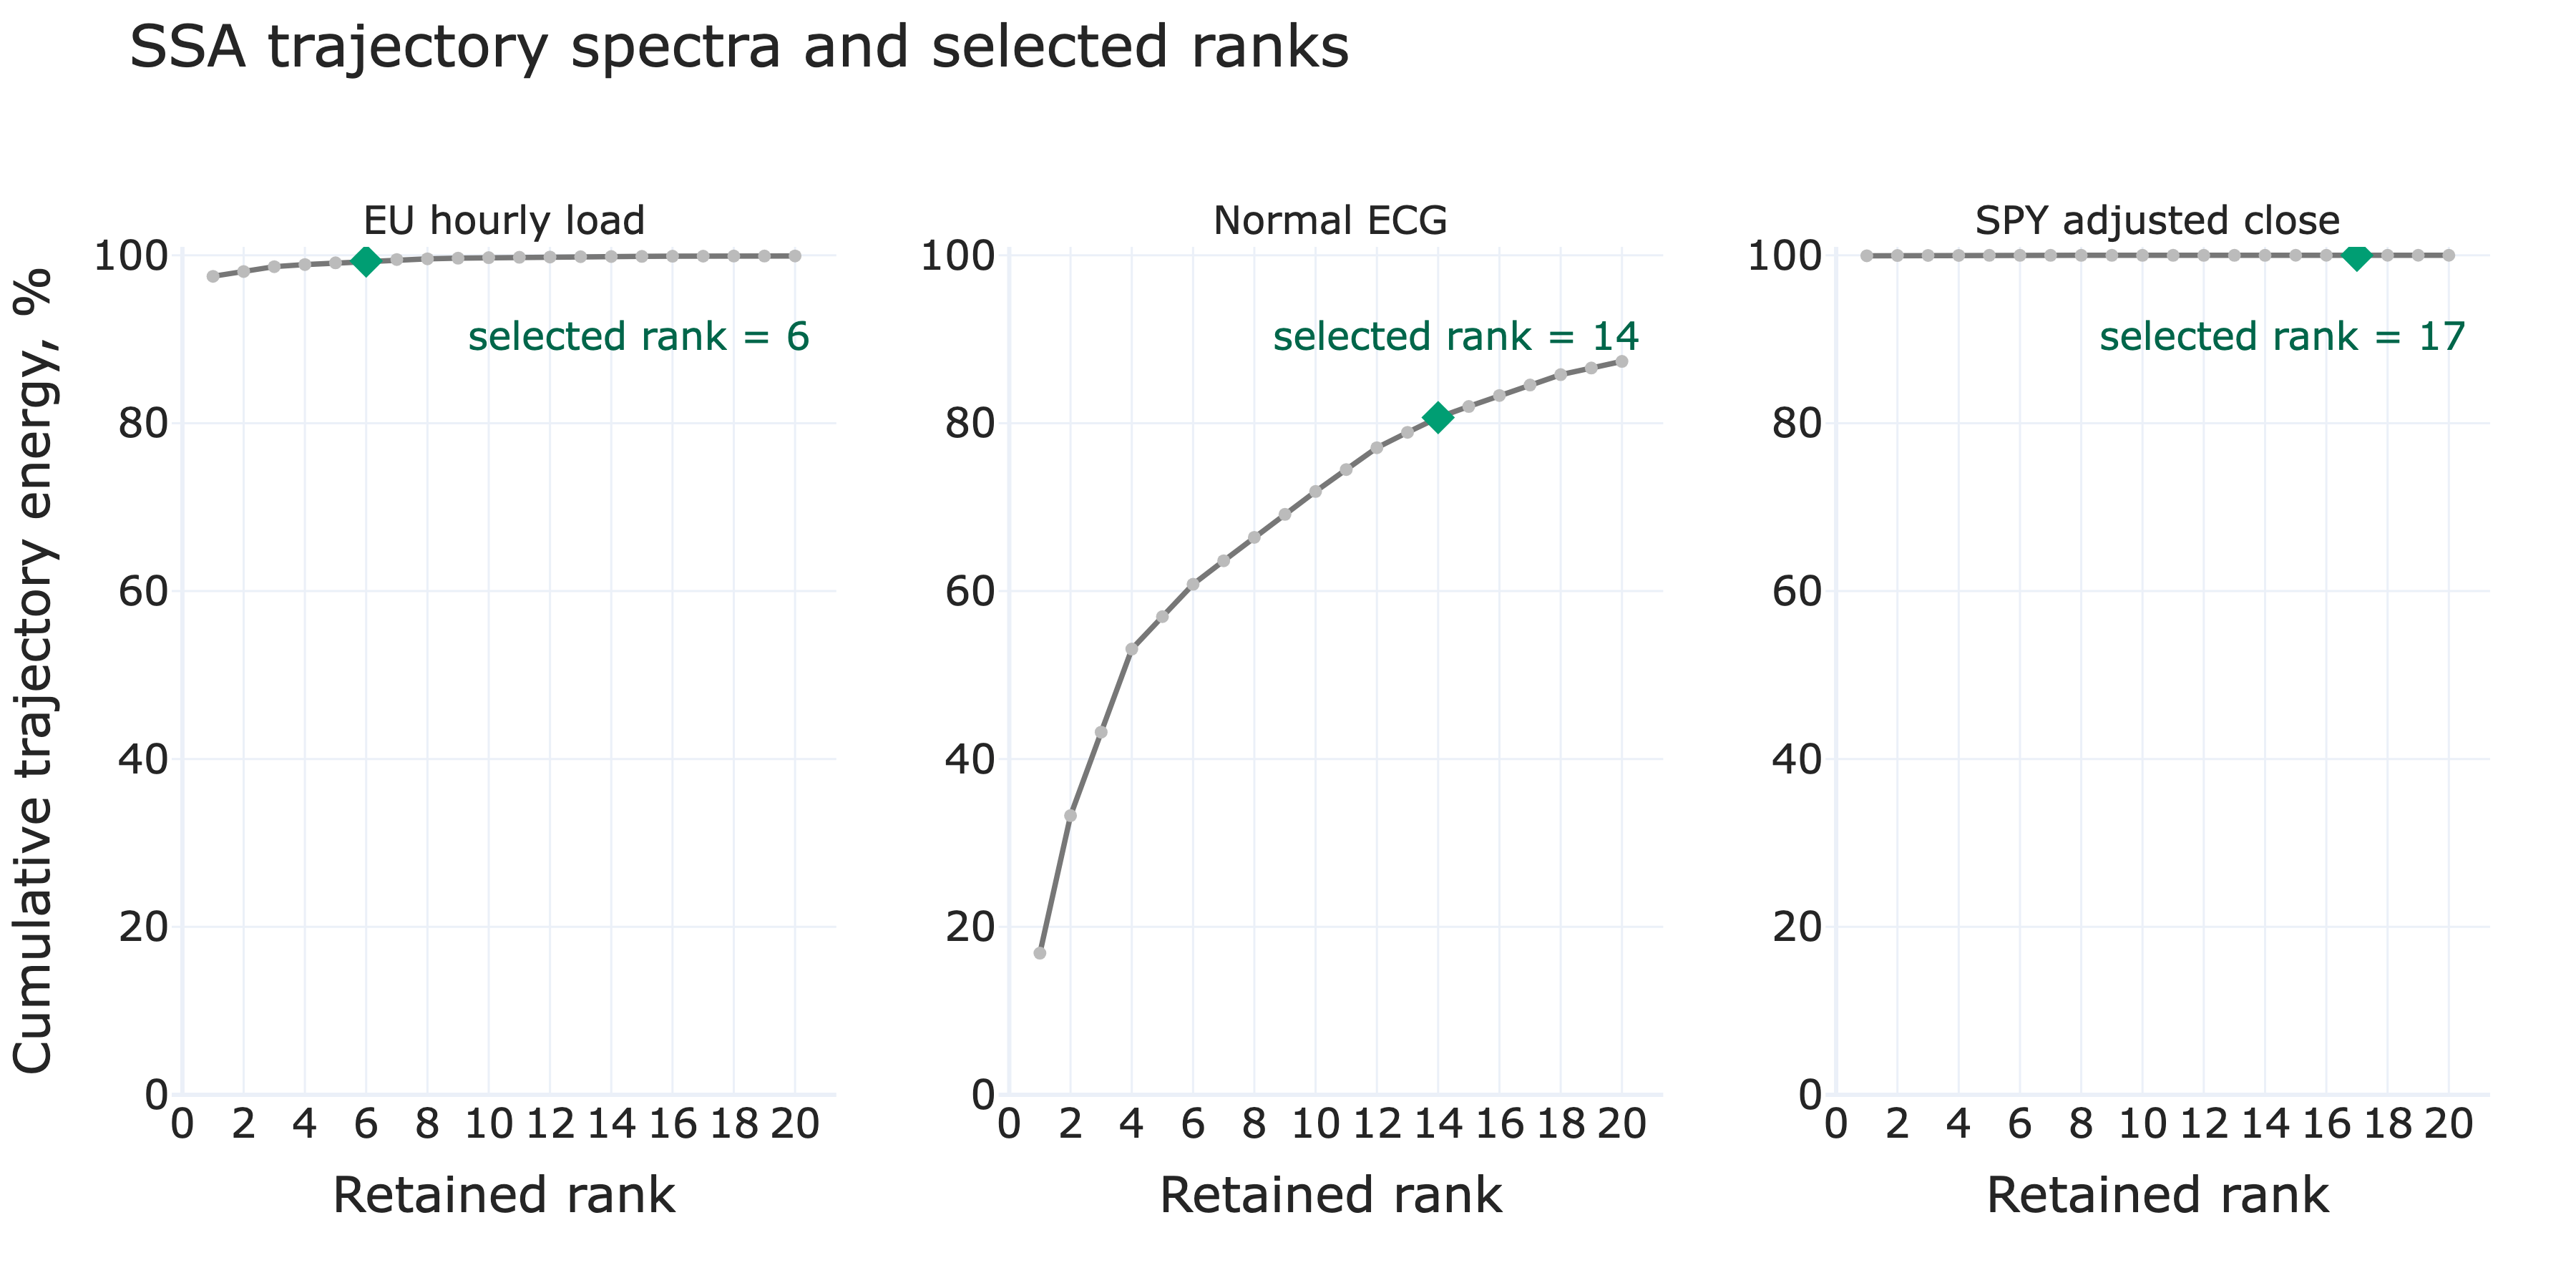

+---------------------------------------------------------------------------------------+
|                      SSA diagnostics for the final 14-step block                      |
+--------------------+----------+---------------+--------------------+------------------+
| Series             | Window L | Selected rank | Retained energy, % | 14-step sMAPE, % |
+--------------------+----------+---------------+--------------------+------------------+
| EU hourly load     | 168      | 6             | 99.306             | 5.275            |
| Normal ECG         | 140      | 14            | 80.671             | 68.699           |
| SPY adjusted close | 60       | 17            | 99.997             | 1.479            |
+--------------------+----------+---------------+--------------------+------------------+


In [11]:
fig = make_subplots(
    rows=1, cols=3, horizontal_spacing=0.07,
    subplot_titles=[item.label for item in series.values()],
)
ssa_rows = []

for col, item in enumerate(series.values(), start=1):
    diagnostic = last_diagnostics[item.key]["ssa"]
    energy = diagnostic["singular_values"] ** 2
    cumulative = 100 * np.cumsum(energy) / energy.sum()
    component = np.arange(1, min(20, len(cumulative)) + 1)
    rank = diagnostic["rank"]

    fig.add_trace(
        go.Scatter(
            x=component,
            y=cumulative[:len(component)],
            mode="lines+markers",
            name="Cumulative trajectory energy",
            showlegend=False,
            line=dict(color="#777777", width=2.5),
            marker=dict(size=6, color="#BBBBBB"),
            hovertemplate="Rank %{x}<br>Retained energy=%{y:.3f}%<extra></extra>",
        ),
        row=1,
        col=col,
    )
    if rank <= len(component):
        fig.add_trace(
            go.Scatter(
                x=[rank],
                y=[cumulative[rank - 1]],
                mode="markers",
                name="Selected rank",
                showlegend=False,
                marker=dict(color=METHOD_COLORS["SSA"], size=12, symbol="diamond"),
                hovertemplate="Selected rank=%{x}<br>Retained energy=%{y:.3f}%<extra></extra>",
            ),
            row=1,
            col=col,
        )
    axis_suffix = "" if col == 1 else str(col)
    fig.add_annotation(
        x=0.97, y=0.93, xref=f"x{axis_suffix} domain", yref=f"y{axis_suffix} domain",
        text=f"selected rank = {rank}", showarrow=False, xanchor="right",
        font=dict(size=18, color="#00664A"),
    )
    fig.update_xaxes(title_text="Retained rank", dtick=2, row=1, col=col)
    fig.update_yaxes(
        title_text="Cumulative trajectory energy, %" if col == 1 else None,
        range=[0, 101],
        row=1,
        col=col,
    )

    ssa_rows.append({
        "Series": item.label,
        "Window L": item.ssa_window,
        "Selected rank": rank,
        "Retained energy, %": 100 * diagnostic["retained_energy"],
        "14-step sMAPE, %": smape(last_diagnostics[item.key]["actual"],
                                   last_diagnostics[item.key]["predictions"]["SSA"]),
    })

fig.update_layout(title="SSA trajectory spectra and selected ranks")
show_and_save(
    fig, "ssa_spectra",
    "Cumulative SSA energy and validation-selected ranks",
    height=600, top_margin=115, bottom_margin=90,
)

show_table(pd.DataFrame(ssa_rows), "SSA diagnostics for the final 14-step block", precision=3, max_width=25)


Cumulative SVD energy is computed from the training prefix at the final 14-step origin. Rank is selected on the preceding training suffix.

At the final 14-step origin, validation selects rank 6 for load, rank 14 for ECG and rank 17 for SPY. The retained trajectory energy is 99.31%, 80.67% and 99.997%, respectively. These percentages are not forecast scores: SPY's level and trend concentrate almost all raw energy in a few directions, but that compact representation does not identify the next price movement.

Load is the most suitable SSA case. Six components preserve enough daily structure to reach 5.28% sMAPE on the displayed block, better than the seasonal baseline but behind local approximation. ECG spreads its energy over many components; even fourteen retain only 80.67%, reflecting detailed morphology, noise and the concatenation boundary. Its 68.70% displayed-block sMAPE shows that a globally smooth recurrent extension does not reproduce the sharp end-of-beat change. SPY's high selected rank follows the validation suffix closely, but the forecast remains a smooth continuation of level rather than a model of returns.



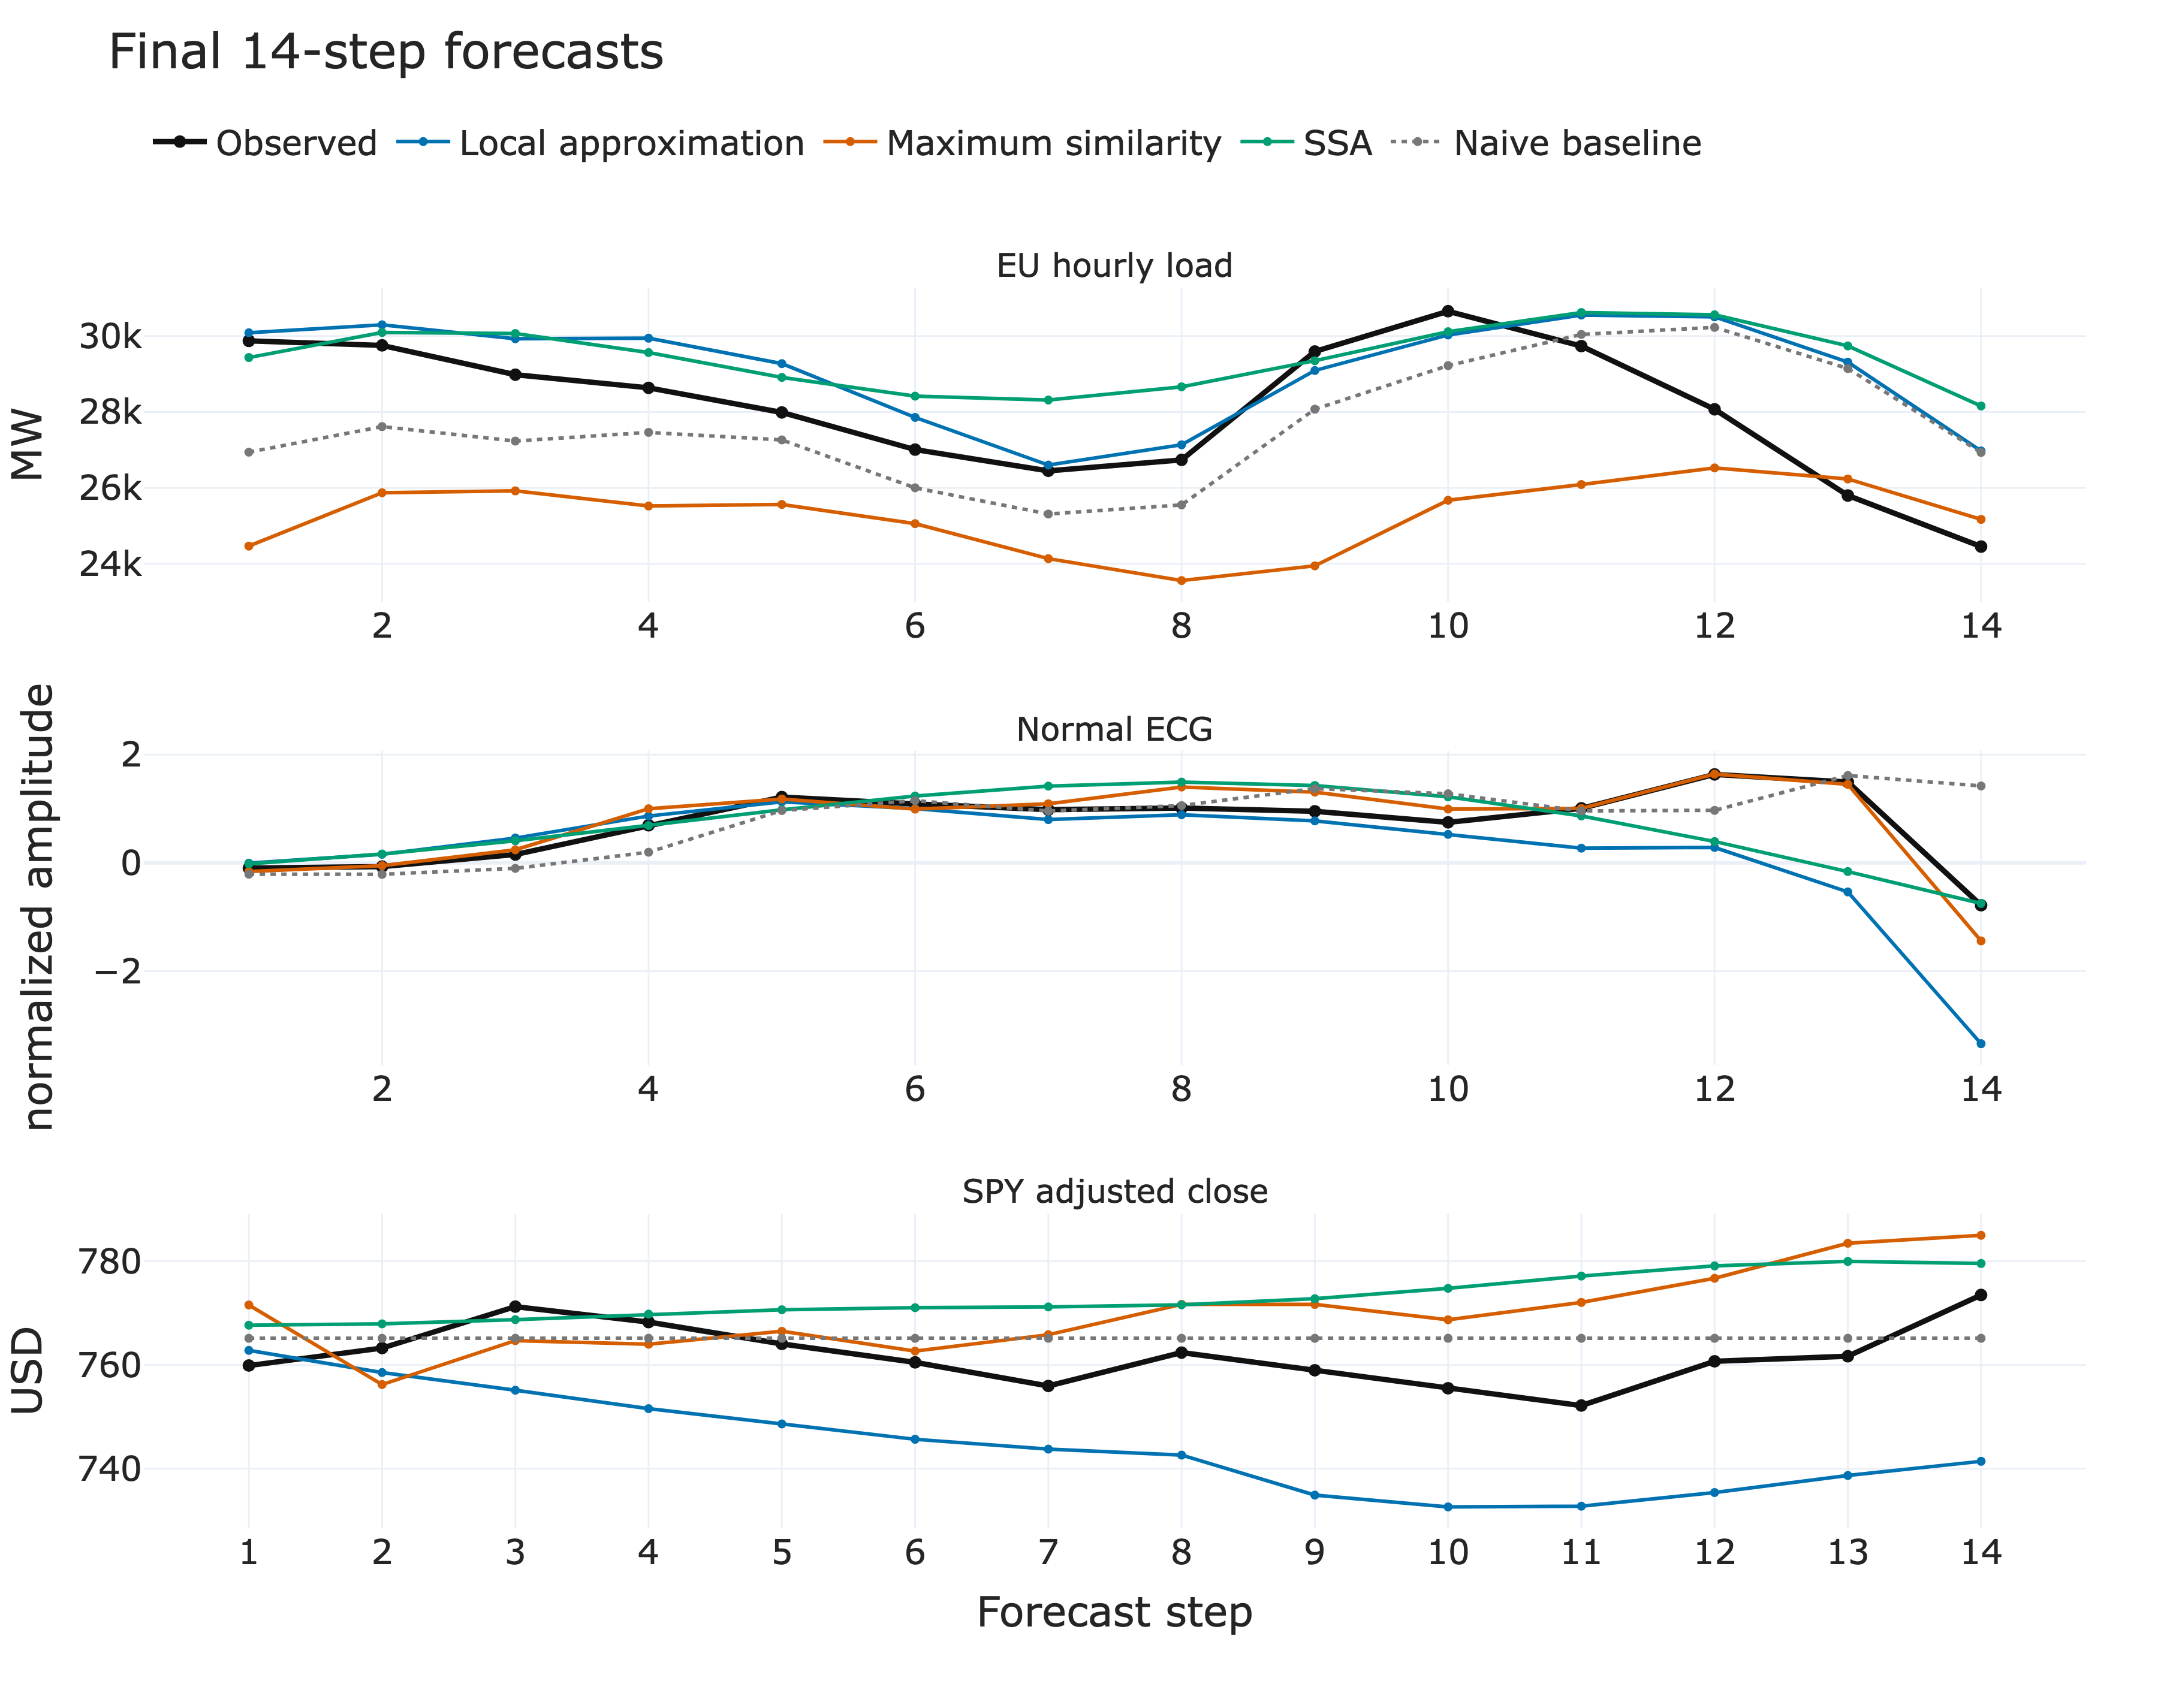

In [12]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.12,
    subplot_titles=[item.label for item in series.values()],
)

for row, item in enumerate(series.values(), start=1):
    record = last_diagnostics[item.key]
    x = np.arange(1, 15)
    fig.add_trace(
        go.Scatter(
            x=x,
            y=record["actual"],
            mode="lines+markers",
            name="Observed",
            legendgroup="Observed",
            showlegend=row == 1,
            line=dict(color="#111111", width=3),
            marker=dict(size=7),
        ),
        row=row,
        col=1,
    )
    for method in METHODS:
        fig.add_trace(
            go.Scatter(
                x=x,
                y=record["predictions"][method],
                mode="lines+markers",
                name=method,
                legendgroup=method,
                showlegend=row == 1,
                line=dict(
                    color=METHOD_COLORS[method],
                    width=2,
                    dash="dot" if method == "Naive baseline" else "solid",
                ),
                marker=dict(size=5),
            ),
            row=row,
            col=1,
        )
    fig.update_yaxes(title_text=item.unit, row=row, col=1)

fig.update_xaxes(title_text="Forecast step", dtick=1, row=3, col=1)
fig.update_layout(title="Final 14-step forecasts")
show_and_save(
    fig, "forecast_examples_h14",
    "Observed and forecast paths for final 14-step blocks",
    height=950, top_margin=160, bottom_margin=100, legend_y=1.09,
)


The tenth non-overlapping block at horizon 14 is shown, with every model fitted only on the preceding prefix.

The load paths make the ranking tangible. Local approximation and SSA preserve the daily turning points, while maximum similarity imports a continuation with the wrong level and amplitude. On the displayed block their sMAPE values are 4.08%, 5.28% and 11.20%, respectively; the seasonal baseline reaches 5.99%.

For ECG, maximum similarity happens to transfer the beat shape well in this block, including the rise around steps 11–13. Local approximation extrapolates the terminal negative deflection too aggressively, and SSA smooths it. This single example is better for maximum similarity than its ten-block mean, which is why it is presented as a mechanism illustration rather than as the main accuracy claim.

The SPY panel shows three different forms of unsupported continuation: local approximation drifts downward, maximum similarity imports an upward analogue, and SSA extrapolates a smooth rise. The flat baseline is less expressive but has the lowest error on this block (0.74% sMAPE). For a persistent financial level, extra structure is useful only if it improves on that strong reference.


## 5. Applicability of the methods

**Local approximation** is the strongest choice for the electricity-load series. It can exploit recurring state-dependent daily dynamics without forcing every day to have the same amplitude. Its weakness is recursive drift: neighbourhood quality can deteriorate once predicted values replace observations. It is less convincing for SPY, where proximity mostly reflects smooth price levels, and for longer ECG horizons that cross distinct waveform phases.

**Maximum similarity** is most useful when whole motifs genuinely recur. The one-step ECG result and the final-beat example illustrate this strength. Its forecast variance is high because only one analogue supplies the future. A large history correlation is therefore necessary but not sufficient, and overlapping histories can reduce the method to persistence at very short horizons.

**SSA** is appropriate when a short series is well described by a stable low-rank combination of trend and oscillatory components. It provides a reasonable second-best load forecast once rank is selected chronologically. It is less suitable for abrupt ECG morphology and for a non-stationary price level whose dominant SVD energy says little about future returns. Rank variation across origins is itself a warning that the assumed global subspace is not stable.

### Conclusion

There is no universal winner across these processes. Local approximation is decisively best for hourly load at all three horizons and remains below the seasonal error scale. ECG contains repeatable motifs, so maximum similarity is valuable at one step and can have low absolute error over a full beat, but percentage and absolute metrics disagree near zero and the seasonal reference is difficult to beat consistently. SPY provides the negative result: the small one-step advantage of maximum similarity and the seven-step mean advantage of SSA are too small and unstable to establish improvement over a random walk, while the baseline wins at fourteen steps.

The practical distinction is therefore structural. Local approximation needs recurring nearby states, maximum similarity needs recurring histories **and** continuations, and SSA needs a stable low-rank signal. When those assumptions are absent, a sophisticated forecast can remain visually smooth while adding no reliable predictive information.

## References

- A. Yu. Loskutov, O. L. Kotlyarov, I. A. Istomin, D. I. Zhuravlev. [*Problems of nonlinear dynamics. III. Local methods for time-series forecasting*](https://vmu.phys.msu.ru/toc/2002/6). Moscow University Physics Bulletin, 2002.
- I. A. Chuchueva. [*A time-series forecasting model based on a sample of maximum similarity*](https://www.mbureau.ru/sites/default/files/pdf/Chuchueva-Dissertation.pdf). PhD dissertation, Bauman Moscow State Technical University, 2012.
- N. Golyandina, A. Korobeynikov. [*Basic Singular Spectrum Analysis and Forecasting with R*](https://arxiv.org/abs/1206.6910). Computational Statistics & Data Analysis, 2014.
